# 03. 서빙 파라미터와 측정

01이 남긴 "schedule 안에서 block을 받는다"의 block 쪽은 02a에서 채웠습니다. 여기서는 그 앞의 결정, 곧 이번 step에 어느 요청이 몇 token을 받는가를 채웁니다. 02b에서 본 preempt와 prefix hit의 비용, 바로 앞 02c에서 본 토큰당 바이트와 요청당 고정 state는 숫자로 읽어야 비교할 수 있습니다. 그래서 이 노트북은 두 가지를 합니다. 정거장 5에서 scheduler가 예산을 나누는 규칙을 코드 순서대로 걷고, 그 결정이 client와 서버의 지표에 어떻게 찍히는지 정의부터 읽습니다. 기본값을 외우는 시간이 아닙니다. 기본값이 어디서 정해지고, 지표의 시계가 어디서 시작하는지 찾는 시간입니다.

## 학습 목표

- `schedule()`이 한 step에 하는 일을 순서대로 말한다.
- `max_num_batched_tokens`와 `max_num_seqs`의 기본값이 하드웨어와 진입점에 따라 달라짐을 표로 읽는다.
- chunked prefill과 long prefill threshold의 교환 관계를 설명한다.
- TTFT, ITL, TPOT, E2EL을 코드 정의로 말하고 client 지표와 서버 지표를 구분한다.
- `/metrics` 이름을 읽고 두 시점의 변화량으로 계산한다.
- 한 번에 한 변수만 바꾸는 실험을 설계한다.

## 수업 시간표

| 절 | 내용 | 분 |
|---|---|---:|
| 1 | `schedule()` 한 바퀴와 token budget | 8 |
| 2 | 기본값: 하드웨어와 진입점 | 6 |
| 3 | chunked prefill과 long prefill threshold | 8 |
| 4 | admission과 preemption | 6 |
| 5 | TTFT, ITL, TPOT, E2EL | 9 |
| 6 | `/metrics` 읽기 | 5 |
| 7 | `vllm bench serve`와 한 변수 실험 | 3 |
| 8 | TP, replica, `-O` | 2 |
| 9 | 직접 해보기, 확인 질문, 정리 | 3 |

## 호출 규모

모델 호출 0회, 유료 API 호출 0회, 키와 GPU가 필요 없습니다. 서버를 띄우지 않고, 저장된 실제 클래스 실행 기록(`data/reference_sched.json`)을 읽기만 합니다. 이 노트북의 시간 값은 전부 선언한 toy 상수의 결과이고 측정값이 아닙니다. `/metrics` 표본도 수업이 만든 글입니다.

이제부터 나오는 step 표와 그림은 `vllm_lab.sched_sim`의 결과입니다. **이것은 vLLM이 아니라 수업용 모델입니다.** `schedule()`의 순서와 지표 식을 FCFS, 한 프로세스로 줄여 옮겼을 뿐이고, step 시간은 `toy_step_ms + toy_ms_per_token * token 수`로 **우리가 정한 가정**입니다. 모델링하지 않은 것은 아래 셀이 그대로 출력합니다.

이 모델에는 실제 `Scheduler` 클래스와 대조한 기록이 있습니다(`실제 클래스 실행`, `data/reference_sched.json`과 `docs/reference/sched.md`). v0.32.0의 `Scheduler`를 CPU에서 같은 입력으로 불러 step 행을 비교한 것입니다. 전체 입력 검사(`scheduler_reserve_full_isl`)와 prefix cache를 모두 끈 조건에서는 38개 시나리오의 행이 전부 같았습니다. 둘 중 하나라도 켜면 40개 시나리오 가운데 9개에서 행이 달라집니다. 전체 입력 검사는 `SchedConfig(reserve_full_isl=True)`로 맞출 수 있고, prefix cache 쪽은 이 모델이 다루지 않습니다.

그래서 이 노트북의 step 표에 대해 말할 수 있는 범위는 이렇습니다. token 배정과 preempt는 위 조건에서 실제 클래스와 같았습니다. 시간 칸은 실제 쪽에 없으므로 toy 값은 여전히 가정입니다. 이 기록은 서버 관찰이 아니라 클래스 호출이고, 출력 token은 손으로 만든 값이며, 모델 forward와 GPU와 `/metrics` logger가 없습니다.

In [1]:
import dataclasses
import json
import math

from IPython.display import display

import vllm_lab
from vllm_lab import kv_math, sched_sim, view
from vllm_lab.sched_sim import Req, SchedConfig, SimStuck, run_sim, sweep


def toy_note(config: SchedConfig) -> str:
    """그림 안에 넣는 문구. step 시간이 가정이고 측정이 아니라는 것을 항상 같이 적는다."""
    return (f"toy step = {config.toy_step_ms:g} ms + {config.toy_ms_per_token:g} ms per token. "
            "Direction only, not measured.")


print("기준 소스:", vllm_lab.VLLM_VERSION, vllm_lab.VLLM_COMMIT[:7])
print("sched_sim이 모델링하지 않은 것:")
for line in sched_sim.NOT_MODELED:
    print(" -", line)

기준 소스: 0.32.0 5df63a7
sched_sim이 모델링하지 않은 것:
 - prefix cache는 모델링하지 않는다. 입력 cached_tokens는 첫 스케줄 때 이미 계산한 것으로 칠 뿐이고, preempt 뒤 복귀할 때의 prefix 적중은 없다.
 - speculative decoding의 draft token과 draft slot은 모델링하지 않는다.
 - async scheduling은 모델링하지 않는다. step은 항상 앞 step이 끝난 뒤 시작한다.
 - PRIORITY 정책은 모델링하지 않는다. FCFS만 있고 희생양은 항상 running의 마지막 요청이다.
 - KV watermark와 block 안의 부분 공유는 모델링하지 않는다. block 수만 센다.
 - 실제 시간은 모델링하지 않는다. step 시간은 선언한 toy 상수의 결과다.
 - scheduler_reserve_full_isl의 기본값(vLLM은 True)은 따르지 않는다. SchedConfig.reserve_full_isl의 기본이 False라 첫 chunk에 필요한 block만 보고, 켜면 전체 입력이 들어갈 free block이 없을 때 들여보내지 않는다. vllm/config/scheduler.py:190, vllm/v1/core/sched/scheduler.py:1270, vllm/v1/core/kv_cache_manager.py:522-539
 - cached_tokens 몫도 요청별 block으로 센다. 실제로는 다른 요청이 쥔 block에 적중하면 ref_cnt만 늘고 새 block을 쓰지 않으므로, 이 모델의 쓰는 block과 kv_cache_usage_perc가 더 크게 나온다. vllm/v1/core/single_type_kv_cache_manager.py:245-248, :267-278
 - 적중 block이 free 칸을 쓰는 입장 규칙은 모델링하지 않는다. 실제로는 ref_cnt 0으로 free queue에 있는 적중 block도 free

## 1. `schedule()` 한 바퀴와 token budget

step은 GPU forward 한 번이고, 그 앞에서 `schedule()`이 한 번 돕니다. 이 함수가 답하는 질문은 둘입니다. 이번 step에 **어느 요청이**, **몇 token을** 계산하는가. 판단 재료는 요청마다 있는 두 수입니다. 지금까지 계산한 수 `num_computed_tokens`와 계산해야 할 전체 수 `num_tokens_with_spec`입니다. scheduler에는 prefill 단계도 decode 단계도 없습니다(P3-21). 프롬프트가 많이 남은 요청은 두 수의 차이가 크고 decode 중인 요청은 차이가 1일 뿐이며, 이 함수는 그 차이를 메워 나갑니다.

**이름이 비슷한 상한 둘을 구분합니다.**

- `max_num_batched_tokens`는 **한 step에 계산할 token 합**의 예산(token budget)입니다(P3-03). 요청 하나의 문맥 길이가 아닙니다. 문맥 길이는 `max_model_len`입니다. 코드의 예산은 정확히는 둘입니다. `token_budget`은 `max_num_scheduled_tokens`에서 시작하고, 이 값을 따로 주지 않으면 `max_num_batched_tokens`와 같습니다([`scheduler.py:137`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L137), [`vllm.py:2263`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/vllm.py#L2263)). `input_budget`은 `max_num_batched_tokens`에서 시작합니다([`scheduler.py:614`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L614)). 배정할 때마다 둘 다 빼고, speculative decoding이면 `input_budget`에서 요청마다 draft 슬롯 몫을 더 뺍니다([`scheduler.py:857`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L857)). 따로 주지 않고 speculative decoding도 없으면 두 값이 같으므로, 이 노트북은 "예산" 하나로 부릅니다. `sched_sim`도 하나만 셉니다.
- `max_num_seqs`는 **running에 동시에 있을 요청 수**의 상한입니다(P3-01). 입력을 기다리는 streaming 세션도 이 수에 듭니다([`scheduler.py:922`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L922)). 상한에 닿으면 waiting에서 더 꺼내지 않을 뿐, 이미 running인 요청을 쫓아내지는 않습니다.

예산이 남아도 `max_num_seqs`에 닿으면 새 요청은 들어오지 못하고, `max_num_seqs`가 남아도 예산이 0이면 들어오지 못합니다. 둘은 서로 다른 축입니다.

**공식 문서.** 최적화 문서가 예약 순서([`optimization.md:53`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/configuration/optimization.md#L53))와 예산의 효과([`optimization.md:60`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/configuration/optimization.md#L60) 아래)를 설명합니다. 순서 설명에는 코드와 어긋나는 대목이 있어 뒤에 표로 적습니다. `--max-num-seqs`는 DP rank마다 적용된다고 데이터 병렬 문서가 적습니다([`data_parallel_deployment.md:27`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/serving/data_parallel_deployment.md#L27)).

**코드.** `schedule()`을 위에서 아래로 읽으면 이렇습니다.

| 순서 | `schedule()`이 하는 일 | 코드 |
|---:|---|---|
| 1 | `token_budget`과 `input_budget`을 채운다. 별도 설정이 없으면 둘 다 `max_num_batched_tokens` 값이다 | [`scheduler.py:611`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L611), [`scheduler.py:614`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L614), [`scheduler.py:137`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L137) |
| 2 | 이번 step의 threshold를 정한다(3절) | [`scheduler.py:640`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L640) |
| 3 | running을 앞에서부터 돈다. 예산이 남은 동안만 돈다 | [`scheduler.py:657`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L657) |
| 4 | `num_new_tokens = num_tokens_with_spec + num_output_placeholders - num_computed_tokens`를 계산한다 | [`scheduler.py:703`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L703) |
| 5 | threshold로 자르고 남은 예산으로 자른다 | [`scheduler.py:708`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L708), [`scheduler.py:710`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L710) |
| 6 | `allocate_slots`로 block을 받는다. 실패하면 preempt한다(4절) | [`scheduler.py:776`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L776) |
| 7 | 두 예산에서 뺀다 | [`scheduler.py:856`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L856), [`scheduler.py:857`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L857) |
| 8 | 이번 step에 preempt가 없었을 때만 waiting을 본다. 모든 요청을 멈춘 `PAUSED_ALL` 상태에서도 보지 않는다 | [`scheduler.py:899`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L899), [`scheduler.py:900`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L900) |
| 9 | waiting은 running 수가 상한이면 멈춘다. 새 요청의 계산량은 `num_tokens - 계산한 수`다 | [`scheduler.py:923`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L923), [`scheduler.py:1129`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L1129) |

`num_output_placeholders`는 async scheduling이 쓰는 칸이고(P1-43), 5번 행의 두 번째 링크(`scheduler.py:710`)의 `min`에 함께 있는 `input_budget - draft_slots`는 draft 자리를 세는 항입니다. 둘 다 `sched_sim`에는 없습니다.

9번 행의 상한은 코드에서 이름이 다릅니다. `max_num_running_reqs`가 `max_num_seqs`를 받고([`scheduler.py:129`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L129)), `max_num_active_seqs`를 따로 설정하지 않으면 `max_num_active_reqs`가 그 값을 씁니다([`scheduler.py:132`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L132)). 코드에서 `max_num_seqs`를 찾다가 이 이름을 만나도 같은 상한입니다.

### 문서와 코드가 다를 때

| 문서가 말하는 것 | 코드가 말하는 것 | 근거 |
|---|---|---|
| decode 요청을 모두 먼저 묶고 그다음 prefill을 예약한다([`optimization.md:53`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/configuration/optimization.md#L53)) | decode와 prefill을 나누지 않는다. running 큐 전체를 먼저 돌고, 프롬프트가 남은 running 요청도 그 안에서 chunk를 받는다([`scheduler.py:657`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L657)부터 [`scheduler.py:712`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L712)까지). **코드가 맞습니다** | P3-22, P3-20 |

수업에서는 "running 큐 먼저, 그다음 waiting"이라고 말합니다. PDF 대조(D-17)는 "Decode를 먼저"를 일치로 판정했지만 P3-22가 더 정확하므로 P3-22를 따릅니다.

고정 예제 E1을 돌립니다. 이것은 vLLM이 아니라 수업용 모델입니다. `chat`(전체 34, 계산 33)과 `doc`(전체 54, 계산 32)이 running에 있고 `faq`(전체 20)가 waiting에 있습니다. 예산은 32입니다. `num_blocks=11`은 `kv_sim`의 `num_blocks=12`에서 null block을 뺀 값입니다.

**먼저 예측하세요.** `faq`는 첫 step에 몇 token을 받습니까? `chat`과 `doc`이 각각 받을 수를 먼저 계산하고 답을 적으세요.

In [2]:
e1_config = SchedConfig(max_num_batched_tokens=32, num_blocks=11)
e1 = run_sim(sched_sim.e1_workload(), e1_config)
print(toy_note(e1_config))
display(view.table(e1.step_rows()).head(4))
view.trace_table([event for event in e1.events if event["step"] == 1])

toy step = 10 ms + 0.5 ms per token. Direction only, not measured.


,step,start_ms,end_ms,tokens,합계,남은 예산,쓰는 block,preempt
0,1,0.0,26.0,chat:1 doc:22 faq:9,32,0,8,
1,2,26.0,42.5,chat:1 doc:1 faq:11,13,19,9,
2,3,42.5,54.0,chat:1 doc:1 faq:1,3,29,9,
3,4,54.0,65.5,chat:1 doc:1 faq:1,3,29,9,


,step,actor,kind,request_id,detail
0,1,Scheduler,arrive,chat,"{""start_running"": true}"
1,1,Scheduler,arrive,doc,"{""start_running"": true}"
2,1,Scheduler,arrive,faq,"{""server_arrival_ms"": 0.0}"
3,1,Scheduler,schedule_running,chat,"{""tokens"": 1, ""computed"": 33}"
4,1,Scheduler,schedule_running,doc,"{""tokens"": 22, ""computed"": 32}"
5,1,Scheduler,schedule_waiting,faq,"{""tokens"": 9, ""computed"": 0}"
6,1,Scheduler,chunk,faq,"{""tokens"": 9, ""remaining"": 11}"
7,1,Scheduler,first_token,chat,"{""end_ms"": 26.0}"
8,1,Scheduler,first_token,doc,"{""end_ms"": 26.0}"


**관찰할 것.** step 표의 `남은 예산` 칸을 위에서 아래로 읽으세요. 첫 행의 값과 둘째 행의 값이 다른 이유를 `tokens` 칸으로 설명할 수 있어야 합니다. 아래 trace에서는 `kind` 칸의 순서를 읽고, 위 표의 순서 3번과 8번에 대응시켜 보세요.

첫 step은 예산을 끝까지 쓰고 다음 step부터는 남습니다. 예산은 step마다 새로 채워지며 이월되지 않습니다. 둘째 step에서 `chat`과 `doc`이 decode로 넘어가면 각각 1 token만 요구하기 때문입니다. 이것이 "단계 구분이 없다"는 말의 실제 모습입니다. 한 step 안에서 decode 1 token과 prefill 조각이 같은 틀로 배정됩니다.

**왜 이렇게 설계했나.** `schedule()` 앞의 주석이 이유를 직접 적습니다([`scheduler.py:593`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L593)부터). 각 요청의 계산 수를 전체 수까지 끌어올리는 틀 하나에 긴 프롬프트 나누기, 캐시 적중, draft token이 전부 담긴다는 내용입니다. 이슈 #8779는 스케줄링이 공짜가 아니라는 문제의식을 밝히지만 본문에 효과 수치가 없어 수치 근거로 쓸 수 없습니다.

## 2. 기본값: 하드웨어와 진입점

`vllm serve`의 `max_num_batched_tokens` 기본값은 하나가 아닙니다. 값은 `SchedulerConfig`가 아니라 엔진 인자 단계에서 정해집니다. 갈림길은 셋입니다. 장치 메모리, 장치 이름, 그리고 엔진을 만든 진입점(`LLM` 클래스의 `LLM_CLASS`, `vllm serve`의 `OPENAI_API_SERVER`)입니다(P3-02, P3-04, P1-16).

공식 문서에는 이 설명이 없습니다. 기본값 표를 문서에서 찾지 못했습니다(P3-02, P3-04). 근거는 코드뿐입니다.

- 메모리와 이름 조회: [`arg_utils.py:2913`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L2913). 실패하면 메모리 0, 이름 빈 문자열이라 "그 외" 값을 씁니다.
- 160GiB 이상: [`arg_utils.py:2923`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L2923)
- 70GiB 이상이고 이름에 `a100`이 없음: [`arg_utils.py:2933`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L2933). 코드 주석은 H100, H200을 예로 듭니다. 80GB A100은 메모리로는 이 문턱을 넘지만 이름 때문에 여기 들지 못하고 그 외로 갑니다(P3-02, P3-04).
- 그 외: [`arg_utils.py:2945`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L2945). 80GB A100의 `vllm serve` 기본은 여기서 2048 / 256입니다.
- `SchedulerConfig`의 `128`과 `2048`: `DEFAULT_MAX_NUM_SEQS`([`scheduler.py:43`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/scheduler.py#L43))와 `DEFAULT_MAX_NUM_BATCHED_TOKENS`([`scheduler.py:41`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/scheduler.py#L41)). 테스트 편의용이라는 설명은 `max_num_seqs` 필드 설명에 있습니다([`scheduler.py:62`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/scheduler.py#L62)).

CPU, TPU, batched DP MoE는 별도 값이 있지만 수업 범위 밖이라 표에 넣지 않습니다. 아래 지역 함수는 위 세 분기만 옮겼습니다. 메모리 칸은 분기를 보여 주는 **가상 입력**이고 실제 장치 사양이 아닙니다. A100 행의 80은 80GB 제품을 흉내 낸 값입니다.

In [3]:
LLM_CLASS, OPENAI_API_SERVER = "LLM_CLASS", "OPENAI_API_SERVER"


def default_limits(memory_gib: float, device_name: str, entry: str) -> dict:
    """vllm/engine/arg_utils.py:2923-2952의 세 분기. 사용자가 값을 주지 않았을 때의 출발값이다."""
    name = device_name.lower()
    if memory_gib >= 160:
        tokens, seqs = {LLM_CLASS: 16384, OPENAI_API_SERVER: 16384}, 1024
    elif memory_gib >= 70 and "a100" not in name:
        tokens, seqs = {LLM_CLASS: 16384, OPENAI_API_SERVER: 8192}, 1024
    else:
        tokens, seqs = {LLM_CLASS: 8192, OPENAI_API_SERVER: 2048}, 256
    return {"메모리(가상, GiB)": memory_gib, "장치 이름": device_name or "(조회 실패)", "진입점": entry,
            "max_num_batched_tokens": tokens[entry], "max_num_seqs": seqs}


view.table([
    default_limits(200, "toy-200g", LLM_CLASS),
    default_limits(200, "toy-200g", OPENAI_API_SERVER),
    default_limits(100, "NVIDIA H200", LLM_CLASS),
    default_limits(100, "NVIDIA H200", OPENAI_API_SERVER),
    default_limits(80, "NVIDIA A100", OPENAI_API_SERVER),
    default_limits(24, "toy-24g", OPENAI_API_SERVER),
    default_limits(0, "", OPENAI_API_SERVER),
])

,"메모리(가상, GiB)",장치 이름,진입점,max_num_batched_tokens,max_num_seqs
0,200,toy-200g,LLM_CLASS,16384,1024
1,200,toy-200g,OPENAI_API_SERVER,16384,1024
2,100,NVIDIA H200,LLM_CLASS,16384,1024
3,100,NVIDIA H200,OPENAI_API_SERVER,8192,1024
4,80,NVIDIA A100,OPENAI_API_SERVER,2048,256
5,24,toy-24g,OPENAI_API_SERVER,2048,256
6,0,(조회 실패),OPENAI_API_SERVER,2048,256


출발값 뒤에 보정이 세 번 더 있고, 모두 **사용자가 값을 주지 않았을 때만** 일어납니다(P3-06, D-04, D-20).

1. `--performance-mode throughput`이면 두 값을 2배로 합니다. 기본 모드는 `balanced`입니다: [`arg_utils.py:3130`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L3130), [`vllm.py:433`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/vllm.py#L433)
2. chunked prefill이 꺼져 있으면 예산을 `max_model_len` 이상으로 올립니다: [`arg_utils.py:3140`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L3140)
3. 예산의 상한을 `max_num_seqs * max_model_len`으로 둡니다: [`arg_utils.py:3167`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L3167). 마지막으로 `max_num_seqs`를 예산 이하로 자릅니다: [`arg_utils.py:3180`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L3180)

코드에는 이 사이에 멀티모달 모델의 바닥값 보정도 있는데, 아래 산수에서는 뺐습니다.

이 보정들도 공식 문서에는 이 설명이 없습니다. 메모리 예산 쪽의 `--gpu-memory-utilization`은 기본 0.92이고 범위는 0 초과 1 이하입니다([`cache.py:102`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L102)). GPU 전체 메모리에 곱해 쓰는 인스턴스별 한도입니다([`utils.py:725`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/utils.py#L725), P3-08, D-03). `--kv-cache-memory-bytes`([`arg_utils.py:1363`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L1363))를 주면 KV 크기는 이 비율을 보지 않습니다([`cache.py:257`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L257)). `--max-model-len`을 주지 않으면 모델 config에서 정하고, `-1`이나 `auto`면 메모리에 들어가는 최대 길이를 고릅니다([`model.py:245`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/model.py#L245), [`arg_utils.py:966`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L966), P3-09). `--max-model-len`을 정하는 과정도 공식 문서에서 찾지 못해 코드만 근거입니다(P3-09).

In [4]:
def after_adjustments(tokens: int, seqs: int, *, mode: str = "balanced", chunked: bool = True,
                      max_model_len: int, user_tokens: int | None = None, user_seqs: int | None = None) -> dict:
    """vllm/engine/arg_utils.py:3130-3180의 보정 순서를 옮긴 산수. 멀티모달 바닥값은 뺐다."""
    t = user_tokens if user_tokens is not None else tokens
    s = user_seqs if user_seqs is not None else seqs
    if mode == "throughput":
        t = t * 2 if user_tokens is None else t
        s = s * 2 if user_seqs is None else s
    if user_tokens is None:
        if not chunked:
            t = max(max_model_len, t)
        t = min(s * max_model_len, t)
    if user_seqs is None:
        s = min(s, t)
    return {"mode": mode, "chunked": chunked, "max_model_len": max_model_len,
            "사용자 예산": "-" if user_tokens is None else user_tokens, "결과 예산": t, "결과 max_num_seqs": s}


view.table([
    after_adjustments(8192, 1024, max_model_len=32768),
    after_adjustments(8192, 1024, mode="throughput", max_model_len=32768),
    after_adjustments(8192, 1024, mode="throughput", max_model_len=32768, user_tokens=4096),
    after_adjustments(8192, 1024, chunked=False, max_model_len=32768),
    after_adjustments(2048, 256, max_model_len=4),
])

,mode,chunked,max_model_len,사용자 예산,결과 예산,결과 max_num_seqs
0,balanced,True,32768,-,8192,1024
1,throughput,True,32768,-,16384,2048
2,throughput,True,32768,4096,4096,2048
3,balanced,False,32768,-,32768,1024
4,balanced,True,4,-,1024,256


**관찰할 것.** 위 두 표에서 진입점만 다른 행을 찾아 예산 칸을 비교하세요. 아래 표에서는 `사용자 예산`이 있는 행의 `결과 예산` 칸이 다른 행과 어떻게 다른지, `max_model_len=4` 행의 `결과 예산` 칸이 어떤 곱에 눌렸는지 읽으세요. `max_model_len` 값은 산수용 입력입니다.

이 표들은 v0.32.0 코드의 산수입니다. 수업 Pod는 `Day07/README.md:75` 기준 v0.28.1rc1 dev 빌드이므로(R-01) 그 서버의 기본값이 이 표와 같다고 말하지 않습니다.

### 문서와 코드가 다를 때

| 문서가 말하는 것 | 코드가 말하는 것 | 근거 |
|---|---|---|
| 지표 예시 출력에 `gpu_memory_utilization="0.9"`가 보인다([`metrics.md:386`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/metrics.md#L386)) | 기본값은 0.92이고 필드 설명도 0.92다([`cache.py:102`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L102)). **코드가 맞습니다.** 예시 출력을 기본값 근거로 삼지 않습니다 | P3-07 |

**왜 이렇게 설계했나.** A100을 따로 빼는 분기에는 이유가 주석으로 남아 있습니다. 이 분기 앞의 주석은 큰 값이 A100의 처리량을 낮춘다고 적고 PR #17885를 가리킵니다([`arg_utils.py:2920`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L2920), P3-05). PR 본문은 A100의 성능 회귀를 고친다고 쓰고, Llama 70B 처리량을 TP=2일 때 1054.01 → 1438.49, TP=4일 때 3053.03 → 2994.03으로 적습니다. 본문에 원인 설명은 없고 TP=4에서는 오히려 약간 줄었으므로 "큰 값이 처리량을 낮춘다"로 일반화하지 않습니다. 진입점마다 값이 다른 이유를 적은 문장은 소스와 공식 문서에서 찾지 못했습니다.

## 3. chunked prefill과 long prefill threshold

**chunked prefill.** 예산보다 긴 프롬프트를 여러 step에 나눠 계산하는 것입니다. 1절에서 보았듯 별도 단계가 아니라, 남은 예산으로 잘라 주는 틀의 결과입니다(P3-21). 예외가 하나 있습니다. DP prefill balancing은 `is_prefill_chunk`를 보고 prefill을 미룹니다([`scheduler.py:634`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L634), [`scheduler.py:686`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L686), [`scheduler.py:1113`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L1113)). 수업 모델에는 없습니다. 세 가지를 기억합니다. 항상 켜짐이 아니라 모델이 지원할 때 켜집니다(P3-10, D-17). 끄면 예산보다 긴 새 요청은 이번 step에 못 들어가고 waiting 순회가 거기서 멈추므로, 뒤에 짧은 요청이 있어도 건너뛰지 않습니다. 끈 채로 예산을 `max_model_len`보다 작게 **직접 주면** 서버 시작 때 `ValueError`입니다. 예산을 주지 않으면 2절의 보정이 `max_model_len`까지 올리므로 이 검사에 닿지 않습니다(P3-11). 지원 모델에서 손으로 끄면 충돌이나 잘못된 출력이 날 수 있다는 경고가 나옵니다([`arg_utils.py:3000`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L3000)).

**공식 문서.** 최적화 문서는 "가능하면 켠다"고 적고([`optimization.md:53`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/configuration/optimization.md#L53)), 예산이 작으면 ITL에, 크면 TTFT에 유리하다고 적습니다([`optimization.md:64`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/configuration/optimization.md#L64), [`optimization.md:65`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/configuration/optimization.md#L65)). TTFT는 요청을 보낸 뒤 첫 응답까지의 시간, ITL은 연속한 두 응답 chunk 사이의 간격이고, 정확한 정의는 5절에 있습니다.

**코드.**

- 켜는 조건: [`arg_utils.py:695`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L695), [`arg_utils.py:2990`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L2990), [`arg_utils.py:2993`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L2993). encoder-decoder는 `SchedulerConfig`가 강제로 끕니다([`scheduler.py:292`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/scheduler.py#L292)). `SchedulerConfig`의 `True`는 테스트 편의 기본값입니다.
- 꺼졌을 때 멈추는 곳: [`scheduler.py:1159`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L1159). 이어지는 조건문이 `num_new_tokens`와 남은 예산을 비교합니다.
- 시작 검사: [`scheduler.py:314`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/scheduler.py#L314)

**long prefill threshold.** chunked prefill만으로는 긴 요청 하나가 남은 예산을 다 가져갈 수 있습니다. `--long-prefill-token-threshold`는 요청 하나가 한 step에 받는 token을 이 값으로 자릅니다. 기본은 0이고 꺼짐입니다(P3-12). running과 waiting을 합쳐 요청이 하나뿐이면 적용하지 않습니다. `--long-prefill-token-threshold-adaptive`는 threshold가 0이 아닐 때만 동작하고, 켜면 컷오프가 "예산 / 요청 수" 아래로 내려가지 않습니다(P3-13).

threshold와 adaptive는 공식 문서에는 이 설명이 없습니다.

**코드.** 기본값은 `long_prefill_token_threshold` 필드에 있고([`scheduler.py:79`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/scheduler.py#L79)), 혼자일 때의 예외는 [`scheduler.py:645`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L645)에 있습니다. adaptive는 계산([`scheduler.py:650`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L650))과 설정 필드([`scheduler.py:86`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/scheduler.py#L86))로 나뉩니다. 적용 지점은 running([`scheduler.py:708`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L708))과 waiting([`scheduler.py:1155`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L1155))입니다.

먼저 긴 요청 하나와 짧은 요청 다섯이 섞인 `mixed_workload()`를 threshold 0으로 돌립니다. 아래 표부터 3절 끝까지의 시간은 전부 toy 값입니다.

In [5]:
mixed_base = SchedConfig(max_num_batched_tokens=64, num_blocks=128)
mixed = run_sim(sched_sim.mixed_workload(), mixed_base)
print(toy_note(mixed_base))
view.table(mixed.step_rows()).head(8)

toy step = 10 ms + 0.5 ms per token. Direction only, not measured.


,step,start_ms,end_ms,tokens,합계,남은 예산,쓰는 block,preempt
0,1,0.0,42.0,doc:64,64,0,4,
1,2,42.0,84.0,doc:64,64,0,8,
2,3,84.0,126.0,doc:64,64,0,12,
3,4,126.0,168.0,doc:64,64,0,16,
4,5,168.0,210.0,doc:64,64,0,20,
5,6,210.0,252.0,doc:64,64,0,24,
6,7,252.0,294.0,doc:16 faq-1:30 faq-2:18,64,0,29,
7,8,294.0,326.0,doc:1 faq-1:1 faq-2:12 faq-3:30,44,20,32,


threshold의 두 예외를 작은 입력으로 분리해 봅니다. `doc` 혼자일 때, `faq`와 같이 있을 때, adaptive를 켰을 때 첫 step 배정을 비교합니다.

In [6]:
def first_step(requests: list[Req], **overrides) -> dict:
    config = SchedConfig(max_num_batched_tokens=64, long_prefill_token_threshold=16, **overrides)
    return run_sim(requests, config).steps[0].tokens


alone = [Req("doc", 400, 2)]
pair = [Req("doc", 400, 2), Req("faq", 30, 2)]
view.table([
    {"경우": "doc 혼자, threshold 16", "첫 step": first_step(alone)},
    {"경우": "doc과 faq, threshold 16", "첫 step": first_step(pair)},
    {"경우": "doc과 faq, threshold 16, adaptive", "첫 step": first_step(pair, long_prefill_token_threshold_adaptive=True)},
])

,경우,첫 step
0,"doc 혼자, threshold 16",{'doc': 64}
1,"doc과 faq, threshold 16","{'doc': 16, 'faq': 16}"
2,"doc과 faq, threshold 16, adaptive","{'doc': 32, 'faq': 30}"


**관찰할 것.** 세 행의 `첫 step` 칸에서 `doc`이 받은 token을 비교하세요. 셋째 행의 값을 "예산 / 요청 수"로 손계산해 맞는지 확인하세요.

이제 threshold만 바꿉니다. 예산은 64로 고정합니다. 그래프의 toy step은 `10 ms + 0.5 ms * token 수`이고 **수치는 측정이 아닙니다. 방향만 봅니다.**

**먼저 예측하세요.** threshold를 줄이면 짧은 요청(`faq`)의 평균 TTFT(요청을 보낸 뒤 첫 응답까지의 시간, 정의는 5절)와 긴 요청(`doc`)의 TTFT는 각각 어느 쪽으로 움직입니까? 두 화살표를 적고 실행하세요.

toy step = 10 ms + 0.5 ms per token. Direction only, not measured.


,long_prefill_token_threshold,steps,toy_tokens_per_s,ttft_mean_ms:doc,ttft_mean_ms:faq,itl_mean_ms,e2el_mean_ms
0,0,31,122.58,294.0,353.4,13.30,498.67
1,8,48,96.20,632.5,215.6,14.27,451.58
2,16,37,111.76,517.5,205.2,16.41,448.75
3,32,27,131.03,378.5,217.4,19.19,468.17
4,48,28,128.81,329.5,274.9,16.59,477.50
5,64,31,122.58,294.0,353.4,13.30,498.67


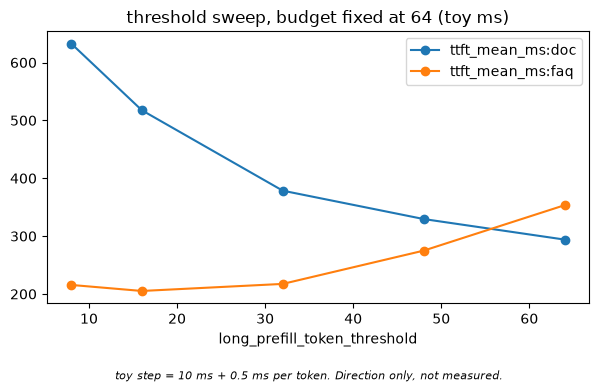

In [7]:
threshold_rows = sweep(sched_sim.mixed_workload(), "long_prefill_token_threshold", [0, 8, 16, 32, 48, 64], mixed_base)
print(toy_note(mixed_base))
display(view.table(threshold_rows, columns=["long_prefill_token_threshold", "steps", "toy_tokens_per_s", "ttft_mean_ms:doc",
                                            "ttft_mean_ms:faq", "itl_mean_ms", "e2el_mean_ms"]).round(2))
view.sweep_chart(threshold_rows[1:], "long_prefill_token_threshold", ["ttft_mean_ms:doc", "ttft_mean_ms:faq"],
                 note=toy_note(mixed_base), title="threshold sweep, budget fixed at 64 (toy ms)")

**관찰할 것.** 그림의 두 선이 threshold가 작아질 때 각각 어느 쪽으로 가는지 읽으세요. 표에서는 threshold 0 행과 값이 똑같은 행을 찾고, 왜 같은지 예산 값으로 설명하세요. 0 행은 "꺼짐"이라 그림에서 뺐습니다.

threshold는 공짜가 아닙니다. 긴 요청의 몫을 짧은 요청에 넘기는 교환이고, 그림의 왼쪽 끝처럼 너무 잘게 자르면 step 수가 늘어 이 모델의 step 고정비가 더 커집니다. 그 고정비 10 ms가 가정이므로 **어느 값이 최적인지는 이 그림으로 말할 수 없습니다.** 말할 수 있는 것은 교환의 방향입니다.

다음은 예산만 바꿉니다. `mixed_workload()`는 긴 요청이 하나뿐이라 ITL이 거의 움직이지 않으므로, 긴 프롬프트가 계속 들어오는 지역 워크로드 `repeat_doc_workload()`를 씁니다. decode가 길게 도는 `faq` 셋과, 40 toy ms마다 도착하는 400 token `doc` 여섯입니다. 이 워크로드는 교환을 눈에 보이게 하려고 수업이 고른 것입니다. 그래프의 수치는 측정이 아닙니다.

toy step = 10 ms + 0.5 ms per token. Direction only, not measured.


,max_num_batched_tokens,steps,toy_tokens_per_s,ttft_mean_ms:doc,ttft_mean_ms:faq,itl_mean_ms,tpot_mean_ms,e2el_mean_ms
0,16,176,73.21,1746.83,72.0,17.76,17.17,1620.72
1,32,92,100.24,1197.50,52.0,25.50,24.28,1436.28
2,64,61,116.06,906.58,56.0,33.05,35.08,1427.28
3,128,60,116.65,784.92,55.0,36.80,48.21,1437.11
4,256,60,116.65,734.08,55.0,40.68,61.70,1497.67
5,512,60,116.65,742.83,55.0,39.98,59.26,1486.39


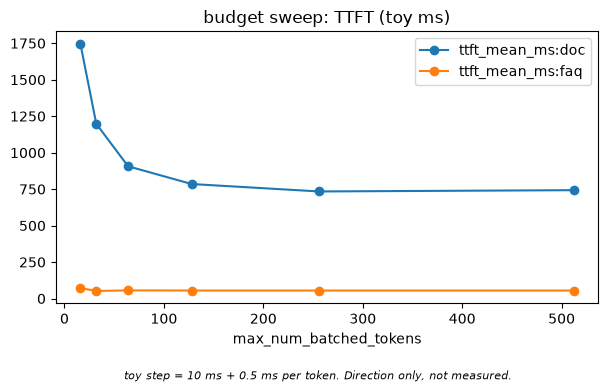

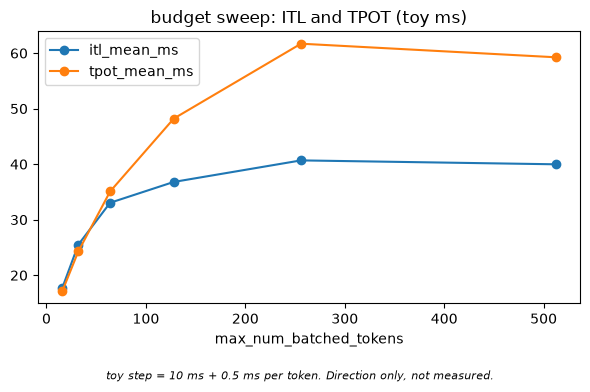

In [8]:
def repeat_doc_workload() -> list[Req]:
    return ([Req(f"faq-{i}", 30, 60) for i in range(1, 4)]
            + [Req(f"doc-{i}", 400, 8, arrival_ms=40.0 * i) for i in range(1, 7)])


budget_base = SchedConfig(max_num_seqs=16, num_blocks=512)
BUDGETS = [16, 32, 64, 128, 256, 512]
budget_rows = sweep(repeat_doc_workload(), "max_num_batched_tokens", BUDGETS, budget_base)
print(toy_note(budget_base))
display(view.table(budget_rows, columns=["max_num_batched_tokens", "steps", "toy_tokens_per_s", "ttft_mean_ms:doc",
                                         "ttft_mean_ms:faq", "itl_mean_ms", "tpot_mean_ms", "e2el_mean_ms"]).round(2))
display(view.sweep_chart(budget_rows, "max_num_batched_tokens", ["ttft_mean_ms:doc", "ttft_mean_ms:faq"],
                         note=toy_note(budget_base), title="budget sweep: TTFT (toy ms)"))
view.sweep_chart(budget_rows, "max_num_batched_tokens", ["itl_mean_ms", "tpot_mean_ms"],
                 note=toy_note(budget_base), title="budget sweep: ITL and TPOT (toy ms)")

**관찰할 것.** 두 그림을 나란히 놓고 예산이 커질 때 `ttft_mean_ms:doc`과 `itl_mean_ms`가 각각 어디로 가는지 읽으세요. 표에서 `toy_tokens_per_s`가 어느 예산부터 더 늘지 않는지도 찾으세요.

`ttft_mean_ms:faq` 선이 거의 평평한 것은 이 워크로드에서 `faq`가 `doc`보다 먼저 도착해 예산을 두고 다툴 상대가 없기 때문입니다. 방향은 문서의 서술([`optimization.md:64`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/configuration/optimization.md#L64), [`optimization.md:65`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/configuration/optimization.md#L65))과 같은 쪽입니다. 그러나 이것은 문서를 증명하지 못합니다. token이 많은 step이 오래 걸린다는 **가정을 우리가 넣었기 때문에** 나온 결과입니다. 해보기 3에서 그 가정을 빼 봅니다.

In [9]:
# 실패 재현: chunked prefill을 끄고 예산을 max_model_len보다 작게 둔다
broken = SchedConfig(max_num_batched_tokens=32, enable_chunked_prefill=False, max_model_len=4096)
try:
    run_sim(sched_sim.mixed_workload(), broken)
except ValueError as error:
    print("검증을 켠 경우:", type(error).__name__, "-", error)

try:
    run_sim(sched_sim.mixed_workload(), broken, validate=False)
except SimStuck as error:
    print("검증을 끈 경우:", type(error).__name__, "-", error)

same_arrival = [dataclasses.replace(req, arrival_ms=0.0) for req in sched_sim.mixed_workload()]
try:
    run_sim(same_arrival, broken, validate=False)
except SimStuck as error:
    print("검증을 끄고 모두 t=0에 도착:", type(error).__name__, "-", error)

boundary = SchedConfig(max_num_batched_tokens=4096, enable_chunked_prefill=False, max_model_len=4096)
boundary.validate()
print("같은 값:", boundary.max_num_batched_tokens, "==", boundary.max_model_len, "-> 예외 없음")

검증을 켠 경우: ValueError - chunked prefill를 끄면 max_num_batched_tokens(32)가 max_model_len(4096) 이상이어야 합니다.
검증을 끈 경우: SimStuck - step 1에서 더 진행할 수 없습니다: 토큰을 하나도 배정하지 못했습니다(마지막 멈춤 stop_waiting_no_chunk). running [], waiting ['doc'], 아직 도착하지 않음 ['faq-1', 'faq-2', 'faq-3', 'faq-4', 'faq-5'].
검증을 끄고 모두 t=0에 도착: SimStuck - step 1에서 더 진행할 수 없습니다: 토큰을 하나도 배정하지 못했습니다(마지막 멈춤 stop_waiting_no_chunk). running [], waiting ['doc', 'faq-1', 'faq-2', 'faq-3', 'faq-4', 'faq-5'], 아직 도착하지 않음 [].
같은 값: 4096 == 4096 -> 예외 없음


**관찰할 것.** 첫 메시지에서 비교되는 값 둘을 찾으세요. 둘째 메시지에서는 어느 멈춤 이유로 끝났는지, 요청이 `running`, `waiting`, `아직 도착하지 않음` 목록에 어떻게 나뉘는지 읽으세요. 이때 `faq`는 왜 막힌 것이 아닙니까? 셋째 메시지는 같은 요청이 모두 t=0에 도착한 경우입니다. `faq-1`의 30 token은 예산 32 안에 들어가는데도 `waiting`에 남아 있는 이유를 FCFS로 설명해 보세요.

실제 검사는 `verify_max_model_len`([`scheduler.py:314`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/scheduler.py#L314))이고 수업 모델은 같은 비교를 옮겼습니다. `SimStuck`은 수업 모델의 예외입니다. vLLM에서는 값을 직접 줬을 때 시작 검사가 먼저 막습니다.

실제 `Scheduler`에서도 같은 갈림이 보입니다(`실제 클래스 실행`, `data/reference_sched.json`). 검사를 거치면 같은 비교에서 설정 오류가 납니다(`chunk_off_validated`, 실제 쪽 `max_model_len`은 2048). 시작 검사를 건너뛰고 만든 `Scheduler`는 예외 없이 0 token을 배정합니다. `waiting`은 늦게 도착하는 입력에서 `doc` 하나이고(`chunk_off_unvalidated`), 모두 같이 도착하는 입력에서 여섯 요청 전부입니다(`chunk_off_unvalidated_same_arrival`).

### 문서와 코드가 다를 때

| 문서가 말하는 것 | 코드가 말하는 것 | 근거 |
|---|---|---|
| chunked prefill을 끄면 `max_num_batched_tokens`가 `max_model_len`보다 "커야" 한다([`optimization.md:70`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/configuration/optimization.md#L70)) | `<` 일 때만 `ValueError`이고 같은 값은 허용한다([`scheduler.py:316`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/scheduler.py#L316)). **코드가 맞습니다** | P3-11 |

**왜 이렇게 설계했나.** 이유가 코드 주석에 있습니다. threshold를 정하는 줄 앞의 주석은 이 값이 긴 prefill이 다른 요청의 예산을 굶기지 못하게 하려고 있고, 혼자일 때는 굶을 상대가 없으니 예산 전부를 쓰게 한다고 적습니다([`scheduler.py:640`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L640)). adaptive의 이유도 주석이 적습니다([`scheduler.py:651`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L651), 공정 몫 아래로 자르지 않기). chunked prefill을 끄는 이유는 encoder-decoder가 지원하지 않는다는 로그 문구([`scheduler.py:299`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/scheduler.py#L299))까지만 확인했습니다. 그림의 모든 값은 toy step의 결과이고 측정이 아닙니다.

## 4. admission과 preemption

요청을 막는 일은 두 층에서 일어납니다. 프로세스도, 결과도, 기본값도 다릅니다.

| | admission | preemption |
|---|---|---|
| 어디서 | API server | EngineCore의 scheduler |
| 언제 | 요청이 들어올 때 | step 안에서 KV block을 받지 못할 때 |
| 설정 | `--max-num-queued-reqs`, `--max-num-queued-tokens` | `--gpu-memory-utilization` 등으로 KV 크기가 간접적으로 정해짐 |
| 기본값 | 둘 다 None. 거절하지 않음(P1-34) | 항상 동작 |
| client가 보는 것 | HTTP 503 | 응답이 늦어짐. 오류는 없음 |
| 지표 | `vllm:admission_rejections`(라벨 `reason`, [`loggers.py:848`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L848)) | `vllm:num_preemptions`, `vllm:request_num_preemptions` |

**admission.** `--max-num-queued-reqs`는 미완료 요청(waiting + running) 수의 상한이고 DP rank를 합쳐 셉니다. `n>1` 요청은 n개로 칩니다([`async_llm.py:322`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/async_llm.py#L322)). 이 검사는 `AsyncLLM` 경로에만 있어 `LLM` 클래스에는 적용되지 않습니다([`protocol.py:71`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/protocol.py#L71), P3-14). `--max-num-queued-tokens`는 prefill 중인 요청의 프롬프트 token 합에 거는 한도이고 TTFT 목표를 지키기 위한 장치입니다. 그 합이 이미 한도 이상이면 거절하며 새 요청의 token은 더해 보지 않습니다([`async_llm.py:365`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/async_llm.py#L365)). chunk로 이미 계산한 양과 prefix cache 적중을 빼지 않아 실제보다 많이 셉니다([`async_llm.py:328`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/async_llm.py#L328), P3-15).

**preemption.** 경로는 다음과 같습니다(P3-23, D-07).

1. `allocate_slots`가 `None`을 돌려줍니다.
2. FCFS면 `running[-1]`을 희생양으로 고릅니다. priority 정책이면 `(priority, arrival_time)`이 가장 큰 요청, 곧 우선순위가 가장 낮고 같으면 가장 늦게 온 요청입니다([`scheduler.py:797`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L797)).
3. block을 반납하고 `num_computed_tokens=0`, 상태 PREEMPTED, `num_preemptions + 1`로 만든 뒤 waiting 맨 앞에 넣습니다. 고른 요청이 자기 자신이어도 여기까지 똑같이 밟고, 그 뒤 running 순회를 멈춥니다. 아래 표의 `preempt(False)` 칸 step 3이 이 경우입니다.
4. 그 step은 waiting을 보지 않습니다.

02b에서 본 대로 복귀할 때는 `num_computed_tokens == 0`이므로 prefix cache를 조회합니다([`scheduler.py:960`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L960)). 덮어써지지 않은 block은 재사용하고, 이미 생성한 출력까지 포함해 나머지 token을 계산합니다([`scheduler.py:1126`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L1126)). 프롬프트 전체를 다시 계산하는 것은 적중이 없을 때뿐입니다(P3-23, P2-37). `sched_sim`은 이 재사용을 모델링하지 않으므로 아래 표의 모델 값은 적중이 없는 경우입니다. KV connector가 block 반납을 미루는 중이면 preempt 없이 멈출 수 있다는 예외도 있고([`scheduler.py:788`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L788), [`scheduler.py:805`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L805)), 수업 모델에는 없습니다.

**공식 문서.** 데이터 병렬 문서는 admission 한도가 서버 전체 기준이라고 적습니다([`data_parallel_deployment.md:29`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/serving/data_parallel_deployment.md#L29)). 최적화 문서는 preempt가 잦으면 비율을 올리라고([`optimization.md:40`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/configuration/optimization.md#L40)), Prometheus로 볼 수 있다고([`optimization.md:45`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/configuration/optimization.md#L45)) 적습니다.

**코드.**

- admission: [`async_llm.py:316`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/async_llm.py#L316), [`scheduler.py:92`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/scheduler.py#L92), [`scheduler.py:105`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/scheduler.py#L105), [`scheduler.py:121`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/scheduler.py#L121)
- preempt 경로: [`scheduler.py:778`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L778), [`scheduler.py:802`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L802), [`scheduler.py:842`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L842), [`scheduler.py:1571`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L1571), [`scheduler.py:1593`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L1593), [`scheduler.py:1613`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L1613), [`scheduler.py:900`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L900)
- 지표: 누적 횟수 `vllm:num_preemptions`([`loggers.py:739`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L739)), 요청별 분포 `vllm:request_num_preemptions`([`loggers.py:1011`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L1011)). 근거 이벤트는 `log_stats`가 켜져 있을 때만 기록됩니다([`scheduler.py:1609`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L1609)). `vllm serve`는 `--disable-log-stats` 기본값이 False라 켜져 있고([`arg_utils.py:612`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L612)), `LLM` 클래스는 따로 주지 않으면 꺼져 있습니다([`llm.py:226`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/llm.py#L226), P3-25).

### 문서와 코드가 다를 때

| 문서가 말하는 것 | 코드가 말하는 것 | 근거 |
|---|---|---|
| preempt되면 `Sequence group 0 is preempted by PreemptionMode.RECOMPUTE ...` 경고를 볼 수 있다([`optimization.md:34`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/configuration/optimization.md#L34)) | `vllm/` 전체에서 `PreemptionMode`와 `Sequence group`이 검색되지 않는다. 이 문구를 찾지 말고 `vllm:num_preemptions`를 읽습니다. **코드가 맞습니다** | P3-24 |

`max_num_seqs`부터 봅니다. `mixed_workload()`에서 이 값만 바꾸면 긴 요청과 짧은 요청의 TTFT가 어떻게 움직이는지 봅니다. 시간은 toy 값입니다.

In [10]:
seqs_rows = sweep(sched_sim.mixed_workload(), "max_num_seqs", [1, 2, 4, 6], mixed_base)
print(toy_note(mixed_base))
view.table(seqs_rows, columns=["max_num_seqs", "steps", "toy_tokens_per_s", "ttft_mean_ms:doc", "ttft_mean_ms:faq",
                               "ttft_p99_ms", "itl_mean_ms", "e2el_mean_ms"]).round(2)

toy step = 10 ms + 0.5 ms per token. Direction only, not measured.


,max_num_seqs,steps,toy_tokens_per_s,ttft_mean_ms:doc,ttft_mean_ms:faq,ttft_p99_ms,itl_mean_ms,e2el_mean_ms
0,1,82,67.26,270.0,703.5,957.98,10.50,753.75
1,2,46,98.70,285.0,460.0,598.58,11.80,568.50
2,4,31,122.58,294.0,353.4,447.70,13.30,498.67
3,6,22,143.40,294.0,310.4,327.50,14.74,479.67


**관찰할 것.** `max_num_seqs=1` 행과 `6` 행에서 `ttft_mean_ms:faq`와 `itl_mean_ms`를 비교하세요. 두 칸이 같은 방향으로 움직입니까?

이제 KV pool을 줄여 preempt를 일으킵니다. `doc_faq_chat()` 세 요청, 예산 32, block 5개입니다. `kv_sim`이 아니라 이 모듈 안에서 block 수만 세는 단순한 모델입니다.

같은 입력을 전체 입력 검사의 두 설정으로 나란히 돌립니다. v0.32.0의 `scheduler_reserve_full_isl`은 기본이 `True`입니다([`scheduler.py:190`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/scheduler.py#L190)). 켜져 있으면 새 요청의 전체 입력이 들어갈 free block이 없을 때 waiting에서 꺼내지 않습니다([`scheduler.py:1270`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L1270), [`kv_cache_manager.py:522`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_manager.py#L522)). 필드 설명은 chunked prefill의 과다 입장과 KV thrashing을 막기 위한 것이라고 적습니다. 수업 모델에서는 `SchedConfig`의 `reserve_full_isl`이고 기본이 `False`입니다. 이 노트북의 다른 표는 모두 끈 쪽입니다. 01에서 block 8개로 본 비교를 여기서는 block 5~10개로 넓힙니다.

**먼저 예측하세요.** block 5개에서 `reserve_full_isl=True`로 켜면 step 2의 `faq`와 step 3의 preempt는 어떻게 됩니까? block을 5개에서 10개로 늘릴 때 `reserve_full_isl=False`의 preempt 수는 줄곧 줄어들까요? 답을 적은 뒤 실행하세요.

In [11]:
preempt_config = SchedConfig(max_num_batched_tokens=32, num_blocks=5, reserve_full_isl=False)
full_isl_config = SchedConfig(max_num_batched_tokens=32, num_blocks=5, reserve_full_isl=True)
preempt_run = run_sim(sched_sim.doc_faq_chat(), preempt_config)
full_isl_run = run_sim(sched_sim.doc_faq_chat(), full_isl_config)
print(toy_note(preempt_config))
display(view.table([
    {"step": off["step"], "tokens(False)": off["tokens"], "preempt(False)": off["preempt"],
     "tokens(True)": on["tokens"], "preempt(True)": on["preempt"]}
    for off, on in zip(preempt_run.step_rows(), full_isl_run.step_rows(), strict=True)
]).head(11))
display(view.trace_table([e for e in preempt_run.events
                          if e["kind"] in ("preempt", "stop_waiting_preempted")]))
full_isl_counters = full_isl_run.counters()
display(view.table([{"지표 이름": name, "reserve_full_isl=False": value, "reserve_full_isl=True": full_isl_counters[name]}
                    for name, value in preempt_run.counters().items()]))

BLOCKS = [5, 6, 7, 8, 9, 10]
sim_off = sweep(sched_sim.doc_faq_chat(), "num_blocks", BLOCKS, SchedConfig(max_num_batched_tokens=32, reserve_full_isl=False))
sim_on = sweep(sched_sim.doc_faq_chat(), "num_blocks", BLOCKS, SchedConfig(max_num_batched_tokens=32, reserve_full_isl=True))
reference = json.loads((vllm_lab.DATA_DIR / "reference_sched.json").read_text(encoding="utf-8"))
real_bases = {base["name"]: base for base in reference["bases"]}


def real_preempts(blocks: int) -> dict:
    """실제 Scheduler 기록에서 네 변형의 preempt 수를 읽는다."""
    return {"실제 " + variant["name"].split("|", 1)[1].replace("|", " "): variant["final"]["preemptions_total"]
            for variant in real_bases[f"preempt_blocks_{blocks}"]["variants"]}


print("실제 칸은 실제 클래스 실행 기록(data/reference_sched.json)입니다. 서버가 아니라 CPU에서 부른 Scheduler 클래스입니다.")
view.table([{"num_blocks": off["num_blocks"], "sched_sim False": off["num_preemptions"], "sched_sim True": on["num_preemptions"],
             **real_preempts(off["num_blocks"])} for off, on in zip(sim_off, sim_on, strict=True)])

toy step = 10 ms + 0.5 ms per token. Direction only, not measured.


,step,tokens(False),preempt(False),tokens(True),preempt(True)
0,1,doc:32,,doc:32,
1,2,doc:22 faq:10,,doc:22,
2,3,doc:1,faq,doc:1,
3,4,doc:1,,doc:1,
4,5,doc:1,,doc:1,
5,6,doc:1,,doc:1,
6,7,doc:1,,doc:1,
7,8,doc:1,,doc:1,
8,9,doc:1,,doc:1,
9,10,faq:20 chat:12,,faq:20 chat:12,


,step,actor,kind,request_id,detail
0,3,Scheduler,preempt,faq,"{""freed_blocks"": 1}"
1,3,Scheduler,stop_waiting_preempted,-,"{""preempted"": [""faq""]}"


,지표 이름,reserve_full_isl=False,reserve_full_isl=True
0,vllm:num_preemptions,1.0,0.0
1,vllm:prefix_cache_queries,108.0,108.0
2,vllm:prefix_cache_hits,0.0,0.0
3,vllm:num_requests_running,0.0,0.0
4,vllm:num_requests_waiting,0.0,0.0
5,vllm:kv_cache_usage_perc,0.0,0.0


실제 칸은 실제 클래스 실행 기록(data/reference_sched.json)입니다. 서버가 아니라 CPU에서 부른 Scheduler 클래스입니다.


,num_blocks,sched_sim False,sched_sim True,실제 isl=off prefix=off,실제 isl=off prefix=on,실제 isl=on prefix=off,실제 isl=on prefix=on
0,5,1,0,1,1,0,0
1,6,0,0,0,0,0,0
2,7,0,0,0,0,0,0
3,8,3,0,3,1,0,0
4,9,0,0,0,0,0,0
5,10,0,0,0,0,0,0


**관찰할 것.** 첫 표에서 step 2와 step 3의 `tokens` 두 칸과 `preempt` 두 칸을 나란히 읽으세요. 지표 표의 `vllm:num_preemptions` 값을 `preempt` 칸과 대조하고, 희생양이 된 요청이 `running[-1]`이었는지 그 step의 `tokens(False)` 칸으로 확인하세요. 마지막 표에서는 `sched_sim` 두 칸이 실제 네 칸 가운데 어느 칸과 같은지 찾고, `num_blocks`를 위에서 아래로 읽으며 block을 늘리면 preempt가 항상 줄어드는지 답하세요.

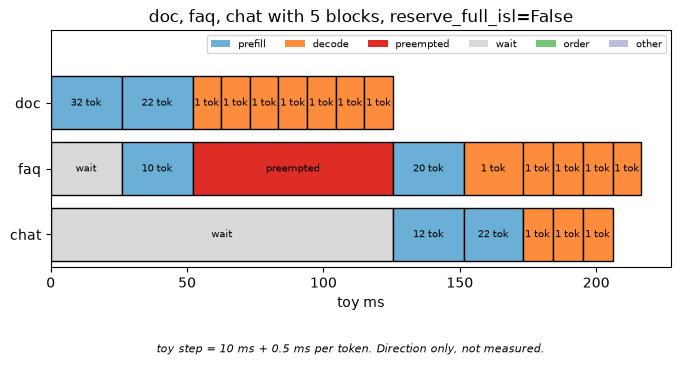

In [12]:
figure = view.timeline(preempt_run.spans(), title="doc, faq, chat with 5 blocks, reserve_full_isl=False", note=toy_note(preempt_config))
figure.subplots_adjust(bottom=0.24)  # 긴 note가 x축 이름과 겹치지 않게 한다
figure.axes[0].set_ylim(2.5, -1.1)  # 범례가 doc 줄을 가리지 않게 위쪽 자리를 만든다
figure

그림은 `reserve_full_isl=False` 쪽입니다. `faq`가 한 번 계산을 받고 다시 대기로 가는 구간을 찾으세요. 앞서 계산한 10 token이 사라지는 값이 여기서 보입니다. 켠 쪽은 step 2에 남는 block이 1개이고 `faq` 20 token은 2개가 필요하므로 `faq`를 들여보내지 않고, 그래서 `faq:10`도 step 3의 preempt도 없습니다.

**block 수 표 읽기(`실제 클래스 실행`).** 실제 칸은 v0.32.0 `Scheduler`를 CPU에서 부른 기록입니다(`data/reference_sched.json`, `docs/reference/sched.md`). `opt-125m`의 config, block 16, 단일 full-attention group, 손으로 만든 출력 token이라는 조건이 붙고 서버를 띄운 관찰이 아닙니다. block 5개와 8개는 작은 pool을 담을 수 있는 `max_model_len`(80, 128)으로 낮춰 다시 돌려도 행이 같았습니다.

| 변형 | block 5, 6, 7, 8, 9, 10의 preempt 수 | 읽는 법 |
|---|---|---|
| `isl=off prefix=off` | 1, 0, 0, 3, 0, 0 | `sched_sim False`와 같습니다 |
| `isl=off prefix=on` | 1, 0, 0, 1, 0, 0 | block 8에서 다릅니다. 적중한 block도 free 칸을 쓰는 수로 세므로(`get_num_blocks_to_allocate`, [`single_type_kv_cache_manager.py:255`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/single_type_kv_cache_manager.py#L255)) `chat`의 복귀 입장이 늦어졌습니다. 수업 모델에 없는 효과입니다 |
| `isl=on prefix=off`, `isl=on prefix=on` | 0, 0, 0, 0, 0, 0 | `isl=on prefix=off`의 행은 `sched_sim True`와 같습니다 |

끈 쪽의 값이 매끈하지 않은 것은 block이 늘면 waiting에서 요청을 더 들여보내고, 그 요청이 나중에 다시 밀려날 수 있기 때문입니다. 결과가 단조롭다고 미리 가정하지 마세요.

켠 쪽의 0은 **이 워크로드의 이 pool에서** 0이라는 뜻입니다. 전체 입력 검사는 입장 때만 작동하므로, running 요청이 생성으로 block 경계를 넘을 때의 preempt는 막지 못합니다. 같은 기록의 `self_preempt_tail`은 켠 변형에도 preempt가 있습니다. `vllm serve`의 prefix caching 기본은 모델이 지원하는지로 정해지므로 어느 칸도 "서버 기본"이라고 말하지 않습니다.

**왜 이렇게 설계했나.** 503은 `QueueOverflowError`의 설명대로 부하 분산기와 client가 다른 인스턴스로 재시도하게 하려는 선택입니다([`exceptions.py:156`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/exceptions.py#L156)). `max_num_queued_tokens`의 과대 집계는 필드 설명대로 의도된 보수적 선택이고([`scheduler.py:121`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/scheduler.py#L121)), 진행 수가 prefill 중에는 API server로 오지 않기 때문이며 안전한 쪽으로 틀린다고 적혀 있습니다. preempt가 swap이 아니라 recompute인 이유는 최적화 문서의 "V1 구조에서 재계산이 오버헤드가 더 낮다"는 문장까지만 확인했고([`optimization.md:47`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/configuration/optimization.md#L47)) PR은 보지 못했습니다.

이 설정들을 offload 계층과 함께 운영하는 이야기는 `04b`에 있습니다.

## 5. TTFT, ITL, TPOT, E2EL

같은 이름의 지표가 두 곳에서 나옵니다. **이름이 같아도 시계가 다릅니다.** 먼저 client 쪽 `vllm bench serve`의 정의입니다. 코드가 streaming 응답의 chunk를 받을 때마다 재는 값이고, `choices`가 있는 chunk만 token chunk로 칩니다.

| 지표 | client 정의 | 공식 문서 | 코드 |
|---|---|---|---|
| TTFT | 보낸 시각부터 `choices`가 있는 첫 데이터까지. text가 비어도 친다(P3-26) | [`cli.md:131`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/benchmarking/cli.md#L131) | [`endpoint_request_func.py:266`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/lib/endpoint_request_func.py#L266)(completions), [`endpoint_request_func.py:438`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/lib/endpoint_request_func.py#L438)(chat) |
| ITL | 연속한 두 chunk의 간격. 같은 chunk 안의 token에 0짜리 간격을 만들지 않는다(P3-27) | [`cli.md:133`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/benchmarking/cli.md#L133), [`cli.md:148`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/benchmarking/cli.md#L148) | [`endpoint_request_func.py:270`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/lib/endpoint_request_func.py#L270), [`endpoint_request_func.py:442`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/lib/endpoint_request_func.py#L442), 집계 [`serve.py:632`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/serve.py#L632) |
| TPOT | `(E2EL - TTFT) / (출력 token 수 - 1)`. 요청마다 한 번 계산한다. 출력이 1개 이하면 통계에서 빠지고 `--goodput` 계산(7절)에서만 0으로 친다(P3-28) | [`cli.md:136`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/benchmarking/cli.md#L136) | [`serve.py:628`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/serve.py#L628), [`serve.py:631`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/serve.py#L631) |
| E2EL | 마지막 token chunk 시각 - 시작 시각. 뒤따르는 usage 전용 chunk는 끝 시각을 옮기지 않는다(P3-29) | [`cli.md:136`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/benchmarking/cli.md#L136) | [`endpoint_request_func.py:447`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/lib/endpoint_request_func.py#L447), [`endpoint_request_func.py:462`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/lib/endpoint_request_func.py#L462) |

출력 token 수는 서버 usage 값을 쓰고, 없으면 tokenizer로 세며, tokenizer도 없으면 1로 둡니다([`serve.py:607`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/serve.py#L607), [`serve.py:609`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/serve.py#L609), [`serve.py:613`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/serve.py#L613), P3-28). `len(itl)`로 세지 않는 이유가 그 주석에 있습니다. 여러 token이 한 chunk에 묶일 수 있기 때문입니다.

**그래서 "ITL = token당 지연"은 틀립니다.** 서버가 `--stream-interval`을 1보다 크게 쓰거나([`scheduler.py:213`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/scheduler.py#L213)) MTP 같은 speculative decoding을 쓰면 chunk 하나에 token이 여럿 담기고, 그때 ITL 표본은 chunk 간격 하나뿐입니다. TPOT은 같은 시간을 모든 token에 나눠 줍니다. 그래서 둘의 평균은 다를 수 있습니다.

**서버 쪽은 측정 지점이 다릅니다.**

| 지표 | 서버 정의 | 공식 문서 | 코드 |
|---|---|---|---|
| TTFT | API server가 요청을 받은 시각(`arrival_time`)부터 첫 출력을 처리한 시각까지(P3-31) | [`metrics.md:56`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/metrics.md#L56) | [`stats.py:521`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/stats.py#L521) |
| ITL | 출력 이벤트마다 직전 출력과의 간격을 한 표본으로 기록한다. 요청당 한 표본이 아니다. EngineCore 출력 시각으로 잰다(P3-31) | [`metrics.md:69`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/metrics.md#L69) | [`stats.py:551`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/stats.py#L551) |
| TPOT | `decode_time / (생성 수 - 1)`. 생성 수가 1 이하면 0으로 기록한다(P3-30) | [`metrics.md:55`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/metrics.md#L55) | [`stats.py:601`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/stats.py#L601), [`stats.py:608`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/stats.py#L608) |
| E2E | 서버 도착부터 완료까지 | [`metrics.md:39`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/metrics.md#L39) | [`stats.py:590`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/stats.py#L590) |
| 대기 시간 | 첫 QUEUED부터 첫 SCHEDULED까지. preempt 뒤 다시 기다린 시간은 넣지 않는다(P3-40) | [`metrics.md:62`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/metrics.md#L62) | [`stats.py:593`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/stats.py#L593) |

두 표를 섞어 쓰면 안 되는 이유는 세 가지입니다. 시작 시각이 다릅니다(client 전송과 API server 도착). 끝 시각의 기준이 다릅니다(client가 받은 시각과 서버가 처리한 시각). 출력이 1개 이하인 요청을 다루는 법이 다릅니다.

### 문서와 코드가 다를 때

| 문서가 말하는 것 | 코드가 말하는 것 | 근거 |
|---|---|---|
| 서버 지표 `vllm:request_time_per_output_token_seconds`를 `(end-to-end latency - TTFT) / (출력 수 - 1)`로 계산한다([`metrics.md:55`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/metrics.md#L55), [`metrics.md:72`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/metrics.md#L72)) | 서버는 `decode_time / (생성 수 - 1)`이고 `decode_time`은 첫 token에서 마지막 token까지다([`stats.py:601`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/stats.py#L601)). 코드의 E2E와 TTFT는 API server의 iteration 시각으로 재므로 문서의 식과 구간은 같아도 시계가 다르다([`stats.py:521`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/stats.py#L521), [`stats.py:590`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/stats.py#L590)). client 벤치마크는 같은 모양의 식을 쓰지만 측정 지점이 또 다르다([`serve.py:628`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/serve.py#L628)). **코드가 맞습니다** | P3-30 |

손으로 먼저 계산합니다. 아래 시각은 수업이 지어낸 입력입니다. `doc`의 응답이 chunk 다섯 개로 왔고 token은 모두 8개입니다. 첫 chunk는 `content`가 비어 있고 reasoning만 있으며, 끝에 usage 전용 chunk가 하나 더 있습니다. 코드 실행 전에 TTFT, E2EL, TPOT을 종이에 적어 보세요. 엔진의 첫 출력과 사람이 보는 첫 답변이 다른 시점이라는 이야기는 Part 5와 6에서 다시 나옵니다(D-36).

In [13]:
hand_chunks = [
    {"t": 0.120, "has_choices": True, "content": "", "reasoning": "r", "completion_tokens": None},
    {"t": 0.150, "has_choices": True, "content": "a", "reasoning": None, "completion_tokens": None},
    {"t": 0.180, "has_choices": True, "content": "b", "reasoning": None, "completion_tokens": None},
    {"t": 0.240, "has_choices": True, "content": "c", "reasoning": None, "completion_tokens": None},
    {"t": 0.270, "has_choices": True, "content": "d", "reasoning": None, "completion_tokens": None},
    {"t": 0.275, "has_choices": False, "content": None, "reasoning": None, "completion_tokens": 8},
]
hand = kv_math.metrics_from_chunks(0.0, hand_chunks)
print("수업이 지어낸 시각이고 측정이 아닙니다.")
display(view.table([{
    "TTFT(s)": hand.ttft_s, "첫 visible(s)": hand.first_visible_s, "E2EL(s)": hand.e2el_s,
    "TPOT(s)": round(hand.tpot_s, 5), "ITL 표본(s)": [round(x, 3) for x in hand.itl_s],
    "chunk 수": hand.num_chunks, "출력 token": hand.output_tokens,
}]))
print("경고:", hand.warnings)

수업이 지어낸 시각이고 측정이 아닙니다.


,TTFT(s),첫 visible(s),E2EL(s),TPOT(s),ITL 표본(s),chunk 수,출력 token
0,0.12,0.15,0.27,0.02143,"[0.03, 0.03, 0.06, 0.03]",5,8


경고: ['한 chunk에 token이 여럿입니다. ITL은 token당 지연이 아닙니다 (출력 8개, chunk 5개)']


**관찰할 것.** `TTFT`와 `첫 visible`이 왜 다른지 첫 chunk의 칸으로 설명하세요. `E2EL`에 0.275가 들어가지 않은 이유도 찾으세요. 그리고 ITL 표본의 수와 출력 token 수를 비교하세요.

이제 시뮬레이터로 chunk에 token이 여럿 담기는 상황을 만듭니다. MTP는 `sched_sim`이 모델링하지 않으므로 `stream_interval`을 대신 씁니다. 첫 chunk를 언제 내는지는 이 모델의 규칙이고 vLLM 동작으로 확인한 것이 아닙니다. `stream_interval`에 따른 TTFT 차이를 vLLM 동작으로 읽지 마세요.

**먼저 예측하세요.** `stream_interval`을 1에서 4로 바꾸면 `doc`의 ITL 표본 수와 평균 ITL, 그리고 TPOT은 각각 어떻게 됩니까?

In [14]:
metric_base = SchedConfig()
interval_rows = []
for interval in (1, 4):
    run = run_sim(sched_sim.doc_faq_chat(), dataclasses.replace(metric_base, stream_interval=interval))
    for metric in run.metrics():
        interval_rows.append({"stream_interval": interval, "요청": metric.request_id, "출력 token": metric.output_tokens,
                              "chunk 수": metric.num_chunks, "ITL 표본 수": len(metric.client_itl_ms),
                              "평균 ITL": metric.client_itl_mean_ms, "TPOT": metric.client_tpot_ms})
print(toy_note(metric_base))
display(view.table(interval_rows).round(2))


def to_chunks(metric: sched_sim.ReqMetrics) -> list[dict]:
    """sched_sim의 chunk 시각(ms)을 kv_math 입력(초)으로 옮기고 usage 전용 chunk를 붙인다."""
    token_chunks = [{"t": t / 1000, "has_choices": True, "content": "x", "reasoning": None, "completion_tokens": None}
                    for t in metric.chunk_times_ms]
    usage = {"t": metric.chunk_times_ms[-1] / 1000 + 0.001, "has_choices": False, "content": None,
             "reasoning": None, "completion_tokens": metric.output_tokens}
    return token_chunks + [usage]


def same(a: float, b_seconds: float) -> bool:
    return math.isclose(a, b_seconds * 1000, abs_tol=1e-9)


agree_rows = []
for metric in run.metrics():
    other = kv_math.metrics_from_chunks(metric.send_ms / 1000, to_chunks(metric))
    agree_rows.append({"요청": metric.request_id,
                       "TTFT 일치": same(metric.client_ttft_ms, other.ttft_s),
                       "E2EL 일치": same(metric.client_e2el_ms, other.e2el_s),
                       "TPOT 일치": same(metric.client_tpot_ms, other.tpot_s),
                       "ITL 일치": all(same(a, b) for a, b in zip(metric.client_itl_ms, other.itl_s, strict=True))})
print("sched_sim과 kv_math.metrics_from_chunks를 같은 시각 열로 대조(stream_interval=4):")
view.table(agree_rows)

toy step = 10 ms + 0.5 ms per token. Direction only, not measured.


,stream_interval,요청,출력 token,chunk 수,ITL 표본 수,평균 ITL,TPOT
0,1,doc,8,8,7,14.21,14.21
1,1,faq,6,6,5,12.60,12.60
2,1,chat,4,4,3,11.50,11.50
3,4,doc,8,3,2,49.75,14.21
4,4,faq,6,3,2,31.50,12.60
5,4,chat,4,2,1,34.50,11.50


sched_sim과 kv_math.metrics_from_chunks를 같은 시각 열로 대조(stream_interval=4):


,요청,TTFT 일치,E2EL 일치,TPOT 일치,ITL 일치
0,doc,True,True,True,True
1,faq,True,True,True,True
2,chat,True,True,True,True


**관찰할 것.** `doc`의 두 행에서 `ITL 표본 수`, `평균 ITL`, `TPOT` 칸을 비교하세요. 어느 칸이 그대로이고 어느 칸이 변했습니까? 아래 표는 두 모듈이 같은 식을 쓰는지 확인하는 것이고, vLLM과 대조한 것은 아닙니다.

client와 서버의 차이를 만듭니다. `toy_network_ms`를 5로 둡니다. 요청이 서버에 닿는 데 5 toy ms, 응답이 돌아오는 데 5 toy ms가 든다는 가정입니다. 출력 1개인 요청에서 TPOT이 어떻게 갈리는지도 함께 봅니다.

In [15]:
network = dataclasses.replace(metric_base, toy_network_ms=5.0)
print(toy_note(network), "toy_network_ms =", network.toy_network_ms)
display(view.table([{
    "요청": m.request_id, "client TTFT": m.client_ttft_ms, "서버 TTFT": m.server_ttft_ms,
    "차이": m.client_ttft_ms - m.server_ttft_ms, "client E2EL": m.client_e2el_ms, "서버 E2E": m.server_e2e_ms,
    "client TPOT": round(m.client_tpot_ms, 2), "서버 TPOT": round(m.server_tpot_ms, 2), "대기(queue)": m.queue_ms,
} for m in run_sim(sched_sim.doc_faq_chat(), network).metrics()]))
one = run_sim([Req("faq", 20, 1)], metric_base).metrics()[0]
print("출력 1개인 요청: client_tpot_ms =", one.client_tpot_ms, ", server_tpot_ms =", one.server_tpot_ms)

toy step = 10 ms + 0.5 ms per token. Direction only, not measured. toy_network_ms = 5.0


,요청,client TTFT,서버 TTFT,차이,client E2EL,서버 E2E,client TPOT,서버 TPOT,대기(queue)
0,doc,62.0,52.0,10.0,161.5,151.5,14.21,14.21,0.0
1,faq,88.0,78.0,10.0,151.0,141.0,12.60,12.60,26.0
2,chat,105.5,95.5,10.0,140.0,130.0,11.50,11.50,52.0


출력 1개인 요청: client_tpot_ms = None , server_tpot_ms = 0.0


**관찰할 것.** `차이` 칸이 `toy_network_ms`의 몇 배인지 읽고 왜 그 배수인지 설명하세요. TPOT 두 칸은 왜 같습니까? 마지막 줄의 두 값은 위 정의표의 어느 문장과 대응합니까?

서버의 시계는 API server 도착 전 구간을 모르므로, TTFT 두 값이 다른 것은 오류가 아닙니다. 이 모델에서는 toy 지연을 왕복으로 넣었으니 차이가 그 왕복 값으로 나옵니다.

**왜 이렇게 설계했나.** 벤치마크 문서는 같은 출력 안의 token에 0짜리 간격을 만들지 않는 이유를 ITL이 출력 사이의 간격만 기록하기 때문이라고 설명하고, TPOT은 시간을 모든 출력 token에 나눠 준다고 적습니다([`cli.md:148`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/benchmarking/cli.md#L148)). 서버와 벤치마크의 TPOT이 달라질 수 있다는 점은 지표 문서가 직접 적습니다([`metrics.md:76`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/metrics.md#L76), 출력 1개 이하를 서버는 0으로 기록하고 벤치마크는 뺍니다). 측정 지점을 왜 둘로 두었는지 적은 문장은 소스와 공식 문서에서 찾지 못했습니다.

## 6. `/metrics` 읽기

`GET /metrics`는 Prometheus 텍스트 형식으로 `vllm:` 접두 지표를 내보냅니다([`metrics.py:77`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/serve/instrumentator/metrics.py#L77), [`metrics.md:24`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/metrics.md#L24), P3-36). `--disable-log-stats`를 주면 기본 stat logger를 만들지 않아 엔진 지표가 등록되지 않습니다([`async_llm.py:196`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/async_llm.py#L196)). 엔진 지표는 거의 모두 라벨 `model_name`, `engine`을 가집니다([`loggers.py:499`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L499), P3-37). 문서 예시 출력의 라벨 이름은 옛 형태라 그대로 믿지 않습니다. 일부 지표는 `reason`, `finished_reason`, `source`, `status`, `stage` 라벨이 더 붙습니다(`stage`는 [`loggers.py:582`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L582)). `vllm:admission_rejections`는 `engine` 없이 `model_name`, `reason`만 가집니다([`loggers.py:852`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L852)). LoRA를 켰을 때만 생기는 `vllm:lora_requests_info`도 다른 라벨을 씁니다([`loggers.py:1103`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L1103), P3-37).

아래 이름은 코드에 등록된 문자열입니다. 비슷한 이름을 짐작해 쓰지 말고 이 표에서 복사합니다. Counter는 노출될 때 이름이 달라지는데, 표 아래에서 다룹니다.

| 항목 | 정확한 이름 | 종류 | 읽는 법 | 코드 |
|---|---|---|---|---|
| prefix cache 조회 | `vllm:prefix_cache_queries` | Counter | **token 수**. 요청 수가 아니다 | [`loggers.py:662`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L662) |
| prefix cache 적중 | `vllm:prefix_cache_hits` | Counter | token 수. 적중률은 hits ÷ queries(우리의 해석) | [`loggers.py:673`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L673) |
| KV 사용률 | `vllm:kv_cache_usage_perc` | Gauge | 이름이 perc지만 **1이 100%** | [`loggers.py:620`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L620) |
| admission 거절 | `vllm:admission_rejections` | Counter | 큐 한도로 거절한 횟수. 라벨 `reason` | [`loggers.py:848`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L848) |
| preemption 누적 | `vllm:num_preemptions` | Counter | 엔진이 preempt한 횟수 누적 | [`loggers.py:739`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L739) |
| 요청별 preemption | `vllm:request_num_preemptions` | Histogram | 요청 하나가 preempt된 횟수 분포 | [`loggers.py:1011`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L1011) |
| waiting | `vllm:num_requests_waiting` | Gauge | 처리 대기 요청 수 | [`loggers.py:538`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L538) |
| 사유별 waiting | `vllm:num_requests_waiting_by_reason` | Gauge | 라벨 `reason`이 `capacity`, `deferred` | [`loggers.py:548`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L548) |
| running | `vllm:num_requests_running` | Gauge | 실행 batch에 든 요청 수 | [`loggers.py:528`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L528) |
| TTFT | `vllm:time_to_first_token_seconds` | Histogram | 서버 도착부터 첫 출력까지(초) | [`loggers.py:931`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L931) |
| ITL | `vllm:inter_token_latency_seconds` | Histogram | 출력 이벤트 사이 간격(초). token당 값이 아님 | [`loggers.py:941`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L941) |
| TPOT(서버) | `vllm:request_time_per_output_token_seconds` | Histogram | 생성 수 1 이하면 0 | [`loggers.py:951`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L951) |
| E2E | `vllm:e2e_request_latency_seconds` | Histogram | 서버 도착부터 완료까지(초) | [`loggers.py:961`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L961) |
| 대기 시간 | `vllm:request_queue_time_seconds` | Histogram | QUEUED부터 첫 SCHEDULED까지. preempt 뒤 재대기는 넣지 않음(P3-40) | [`loggers.py:971`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L971) |
| 구간 시간 | `vllm:request_prefill_time_seconds`, `vllm:request_decode_time_seconds`, `vllm:request_inference_time_seconds` | Histogram | preempt 시간이 구간에 포함된다 | [`loggers.py:991`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L991), [`loggers.py:1001`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L1001), [`loggers.py:981`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L981) |

**복귀 적중은 prefix cache 두 Counter에 들어가지 않습니다.** preempt 뒤 복귀한 요청의 조회와 적중은 `preempted_queries`, `preempted_hits`로 따로 쌓이고(`PrefixCacheStats.record`, [`stats.py:146`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/stats.py#L146)), `/metrics`의 두 Counter는 `queries`, `hits`만 더합니다([`loggers.py:1167`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L1167)). 이 연결은 코드 읽기이고 logger를 돌려 보지는 않았습니다. 두 값이 갈리는 것은 실제 클래스 실행에서 보입니다. block 8개, 전체 입력 검사 끔, prefix cache 켬일 때 `prefix_hits`는 0이고 `preempted_hits`는 16입니다(`data/reference_sched.json`). 그래서 hits ÷ queries로는 복귀 때의 재사용을 읽을 수 없습니다.

**변화량으로 읽습니다.** Counter와 Histogram의 값은 서버가 뜬 뒤의 누적입니다. 실험 하나를 보려면 전후 스냅샷의 차이를 냅니다. Histogram은 `_bucket`, `_sum`, `_count`로 갈라져 나오므로 그 구간의 평균은 `_sum` 변화량 ÷ `_count` 변화량입니다. Gauge는 시점 값이라 뺄셈에 뜻이 없습니다.

**Counter의 `_total`.** 코드에 등록된 이름에는 `_total`이 없고 문서는 노출될 때 붙는다고 적습니다([`metrics.md:633`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/metrics.md#L633)). 이 동작은 prometheus_client 라이브러리 몫입니다(P3-38). 저장소 환경의 prometheus_client 0.26.0으로 `vllm:num_preemptions` Counter를 만들어 보니 단일 프로세스 레지스트리와 `PROMETHEUS_MULTIPROC_DIR` 레지스트리 모두 `vllm:num_preemptions_total`을 냈고, 단일 프로세스는 `_created` 줄도 냈습니다. 그러니 등록 이름 그대로 `/metrics`에서 찾으면 Counter는 찾지 못합니다. 다만 이것은 문서와 라이브러리 실행으로 정한 것이고 **vLLM 서버의 출력으로 본 것은 아닙니다.** 그래서 수업의 권장은 파서가 두 형태를 모두 받게 짜는 것입니다.

아래 Prometheus 텍스트는 **수업이 `SimResult.to_prometheus_text()`로 만든 표본입니다. 서버에서 받은 출력이 아니고 측정값이 아닙니다.** `_bucket` 줄도 없습니다. 첫 줄의 주석이 그 표지입니다. `faq`와 `chat`이 `cached_tokens`를 입력으로 갖고 toy 30 ms에 도착하는 워크로드입니다. prefix cache는 모델링하지 않았고 `cached_tokens`를 그대로 적중으로 셉니다. 같은 입력을 실제 `Scheduler`에 넣은 기록(`실제 클래스 실행`, `sample_shared_prefix`)에서 조회 수와 적중 수는 이 표본과 같습니다. 다른 것은 쓰는 block 수입니다. 실제로는 다른 요청이 쥔 block에 적중하면 ref_cnt만 늘기 때문에 step 3에 실제 6개, 모델 9개입니다. 이 기록은 `PrefixCacheStats` 값이고 `/metrics` 출력이 아닙니다.

In [16]:
# 수업이 만든 표본이다. 실제 /metrics 출력이 아니다.
sample_workload = [Req("doc", 54, 8),
                   Req("faq", 20, 6, arrival_ms=30.0, cached_tokens=16),
                   Req("chat", 34, 4, arrival_ms=30.0, cached_tokens=32)]
sample_run = run_sim(sample_workload, metric_base)
BEFORE_STEP = 2
print("\n".join(sample_run.to_prometheus_text(at_step=BEFORE_STEP).splitlines()[:9]))

# constructed teaching sample, not measured
vllm:num_preemptions{model_name="GLM-5.3-Flash",engine="0"} 0
vllm:prefix_cache_queries{model_name="GLM-5.3-Flash",engine="0"} 54
vllm:prefix_cache_hits{model_name="GLM-5.3-Flash",engine="0"} 0
vllm:num_requests_running{model_name="GLM-5.3-Flash",engine="0"} 1
vllm:num_requests_waiting{model_name="GLM-5.3-Flash",engine="0"} 0
vllm:kv_cache_usage_perc{model_name="GLM-5.3-Flash",engine="0"} 0.0625
vllm:time_to_first_token_seconds_sum{model_name="GLM-5.3-Flash",engine="0"} 0.047
vllm:time_to_first_token_seconds_count{model_name="GLM-5.3-Flash",engine="0"} 1


**관찰할 것.** 첫 줄의 주석과 각 줄의 라벨을 읽으세요. `vllm:kv_cache_usage_perc` 값을 백분율로 읽으면 왜 틀리는지 말하세요. `vllm:num_preemptions` 줄의 이름에 무엇이 없는지도 보세요.

이제 두 시점으로 계산합니다. 위 표본은 코드에 등록된 이름을 그대로 쓴 형태입니다. 노출될 때는 Counter 이름에 `_total`이 붙으므로(P3-38), 표본을 `_total`이 없는 형태와 있는 형태로 각각 만들어 같은 함수로 읽습니다. `값` 칸의 뜻은 Counter는 변화량, Gauge는 뒤 시점 값, Histogram은 구간 평균(초)입니다.

In [17]:
reports = {}
for suffix in ("", "_total"):
    before = kv_math.parse_prometheus(sample_run.to_prometheus_text(at_step=BEFORE_STEP, counter_suffix=suffix))
    after = kv_math.parse_prometheus(sample_run.to_prometheus_text(counter_suffix=suffix))
    reports[suffix or "접미사 없음"] = {"rows": kv_math.metrics_report(before, after),
                                      "hit_rate": kv_math.prefix_hit_rate_delta(before, after),
                                      "before": before, "after": after}
plain, total = reports["접미사 없음"], reports["_total"]
display(view.table([{"항목": a["항목"], "이름": a["이름"], "종류": a["종류"], "값(접미사 없음)": a["값"], "값(_total)": b["값"]}
                    for a, b in zip(plain["rows"], total["rows"], strict=True)]).round(4))

ttft = kv_math.METRIC_NAMES["ttft"]
ttft_sum = kv_math.metric_delta(plain["before"], plain["after"], ttft + "_sum")
ttft_count = kv_math.metric_delta(plain["before"], plain["after"], ttft + "_count")
print(f"TTFT 손계산: _sum 변화량 {ttft_sum:.4f} / _count 변화량 {ttft_count:.0f} = {ttft_sum / ttft_count:.4f} s (toy)")
print(f"적중률(token 기준, 우리의 해석): 접미사 없음 {plain['hit_rate']:.3f}, _total {total['hit_rate']:.3f}")

,항목,이름,종류,값(접미사 없음),값(_total)
0,prefix cache 조회,vllm:prefix_cache_queries,Counter,54.0000,54.0000
1,prefix cache 적중,vllm:prefix_cache_hits,Counter,48.0000,48.0000
2,KV 사용률,vllm:kv_cache_usage_perc,Gauge,0.0000,0.0000
3,preemption 누적,vllm:num_preemptions,Counter,0.0000,0.0000
4,waiting,vllm:num_requests_waiting,Gauge,0.0000,0.0000
5,running,vllm:num_requests_running,Gauge,0.0000,0.0000
6,TTFT(서버),vllm:time_to_first_token_seconds,Histogram,0.0305,0.0305
7,ITL,vllm:inter_token_latency_seconds,Histogram,0.0114,0.0114
8,TPOT(서버),vllm:request_time_per_output_token_seconds,Histogram,0.0114,0.0114
9,E2E,vllm:e2e_request_latency_seconds,Histogram,0.0932,0.0932


TTFT 손계산: _sum 변화량 0.0610 / _count 변화량 2 = 0.0305 s (toy)
적중률(token 기준, 우리의 해석): 접미사 없음 0.889, _total 0.889


**관찰할 것.** 두 `값` 칸이 모든 행에서 같은지 확인하고, `_total`이 붙은 표본에서도 `이름` 칸의 이름으로 값이 읽히는 이유를 `kv_math.metric_value`의 동작으로 설명하세요. `_total`이 붙는다는 것을 알면서도 두 형태를 다 받게 한 이유를, 그 사실을 어디까지 확인했는지와 연결해 말해 보세요. 적중률의 분자와 분모가 token 수라는 것을 표의 앞 두 행으로 확인하세요.

In [18]:
# 실패 재현: 없는 지표를 0으로 읽는 실수
after = plain["after"]
missing = "vllm:num_requests_swapped"
wrong = after.get((missing, ()), 0)
right = kv_math.metric_value(after, missing)
print(f"틀린 읽기: dict.get(..., 0) -> {wrong}  (교체된 요청이 0개라는 뜻으로 읽힌다)")
print(f"맞는 읽기: metric_value(...) -> {right}  (그런 지표가 없다는 뜻이다)")
print("비교:", "vllm:num_preemptions ->", kv_math.metric_value(after, "vllm:num_preemptions"))

틀린 읽기: dict.get(..., 0) -> 0  (교체된 요청이 0개라는 뜻으로 읽힌다)
맞는 읽기: metric_value(...) -> None  (그런 지표가 없다는 뜻이다)
비교: vllm:num_preemptions -> 0.0


**관찰할 것.** 틀린 읽기와 맞는 읽기의 값을 나란히 놓고, 대시보드가 "0"을 그리면 무엇을 잘못 믿게 되는지 말하세요. 비교 줄의 값이 `None`이 아니고 숫자인 것은 무엇을 뜻합니까?

### 문서와 코드가 다를 때

| 문서가 말하는 것 | 코드가 말하는 것 | 근거 |
|---|---|---|
| `vllm:num_requests_running` 항목에 `_swapped`와 `_waiting`이 있고 SWAPPED 상태를 센다([`metrics.md:57`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/metrics.md#L57)) | `vllm/v1/metrics/` 검색 결과 swapped 지표가 없다. 등록된 목록은 running과 waiting이다([`loggers.py:528`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L528), [`loggers.py:538`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L538)). **코드가 맞습니다** | P3-39 |

## 7. `vllm bench serve`와 한 변수 실험

벤치마크 인자는 부하의 모양을 정합니다. 블로그는 이 도구를 다루지 않으므로 문서와 코드만 봅니다.

**공식 문서.** 벤치마크 문서가 부하 인자([`cli.md:704`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/benchmarking/cli.md#L704)부터), ramp-up([`cli.md:658`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/benchmarking/cli.md#L658) 부근), `--ignore-eos`([`cli.md:1255`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/benchmarking/cli.md#L1255))를 설명합니다. `--goodput`은 공식 문서에는 이 설명이 없습니다.

**코드.**

| 인자 | 기본 | 뜻 | 코드 |
|---|---|---|---|
| `--request-rate` | inf | inf면 모두 시각 0에 보낸다. 유한값이면 Poisson 또는 gamma 간격이다(P3-32) | [`serve.py:1698`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/serve.py#L1698) |
| `--burstiness` | 1.0 | 유한 rate에서만 효과가 있다. 1이면 Poisson이다 | [`serve.py:1707`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/serve.py#L1707) |
| `--max-concurrency` | None | 동시 실행 상한. 서버가 못 따라가면 실제 요청률은 `--request-rate`보다 낮아진다 | [`serve.py:1631`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/serve.py#L1631) |
| `--ramp-up-strategy` | None | `linear` 또는 `exponential`. `--ramp-up-start-rps`, `--ramp-up-end-rps`가 둘 다 필요하다(P3-33) | [`serve.py:1917`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/serve.py#L1917) |
| `--percentile-metrics` | 생성 모델은 `ttft,tpot,itl` | 허용 이름은 ttft, tpot, itl, e2el, client_queue_time, e2el_including_client_queue(P3-34) | [`serve.py:1800`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/serve.py#L1800) |
| `--metric-percentiles` | `"99"` | 보고할 백분위 | [`serve.py:1811`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/serve.py#L1811) |
| `--goodput` | 없음 | `KEY:VALUE`(ms) 쌍. 키는 ttft, tpot, e2el만. 요청이 모든 SLO를 동시에 만족해야 good이다(P3-35) | [`serve.py:1820`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/serve.py#L1820) |
| `--ignore-eos` | 꺼짐 | 문서가 쓰라고 권하는 플래그(D-11) | [`serve.py:1784`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/serve.py#L1784), [`serve.py:803`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/serve.py#L803) |

ramp-up은 제약이 있습니다. `--request-rate`를 유한값으로 같이 주면 에러(기본 inf는 괜찮습니다), start가 end보다 크면 에러, exponential에서 start가 0이어도 에러입니다([`serve.py:2030`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/serve.py#L2030)). 이 제약은 문서에 없고 코드에만 있습니다. `--num-prompts`의 기본값은 1000입니다(`DEFAULT_NUM_PROMPTS`, [`datasets.py:70`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/datasets/datasets.py#L70), 인자 정의는 [`datasets.py:1587`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/datasets/datasets.py#L1587)). 그래도 수업의 권장은 **항상 명시하는 것입니다.** 기본값에 기대면 실험을 읽는 사람이 요청 수를 알 수 없습니다.

명령은 이런 모양입니다. **실행하지 않습니다.** 사용법 주석([`serve.py:10`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/serve.py#L10)), `--base-url`([`serve.py:1607`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/serve.py#L1607)), `--input-len`([`serve.py:1653`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/serve.py#L1653)), `--output-len`([`serve.py:1660`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/serve.py#L1660)), 위 표의 인자만 썼고 꺾쇠는 자리 표시자입니다.

```bash
vllm bench serve \
  --backend openai \
  --base-url <서버 주소> --model <서빙 이름> \
  --dataset-name random \
  --input-len <입력 길이> --output-len <출력 길이> --ignore-eos \
  --num-prompts <요청 수> \
  --request-rate <요청률> --max-concurrency <동시 상한> \
  --percentile-metrics ttft,tpot,itl,e2el --metric-percentiles 50,99 \
  --goodput ttft:<ms> tpot:<ms>
```

**한 번에 한 변수.** 절차는 다섯 단계입니다. (1) 기준 설정을 적어 둡니다. (2) `/metrics` 스냅샷을 받습니다. (3) 벤치마크를 돌립니다. (4) 스냅샷을 다시 받아 변화량을 냅니다. (5) 값 하나만 바꿔 되풀이합니다. 두 값을 같이 바꾸면 결과가 움직여도 원인을 나눌 수 없습니다. `sweep()`이 `dataclasses.replace`로 칸 하나만 바꾸는 것도 같은 이유입니다.

**같은 서버에서 되풀이할 때(P3-41).** 같은 서버에 `vllm bench serve`를 되풀이하면 앞 실행이 prefix cache에 남긴 프롬프트가 다시 쓰여 처리량이 부풀려질 수 있습니다([`cli.md:114`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/benchmarking/cli.md#L114)). 문서는 재현 가능한 dataset이면 어느 것이든 해당한다고 적고, 고정된 `--seed`(기본 0)의 random dataset도 재현 가능한 예로 듭니다. 피하려면 `--seed`를 바꾸거나, 서버를 초기화·재시작하거나, 실행 사이에 서버 캐시를 비우는 `vllm bench sweep serve`를 쓰라고 안내합니다. 이것이 한 변수 비교에 중요한 까닭은, 바꾼 값이 아닌 서버의 캐시 상태가 결과를 움직일 수 있기 때문입니다. 그래서 (1)의 기준 설정에 서버를 막 띄운 상태인지도 적어 둡니다.


In [19]:
# 점검표. 숫자는 최적값이 아니라 시험점이다(D-04).
# 왼쪽 숫자는 장치마다 다른 기본값과 같지 않을 수 있다. 8192 / 1024는 H100, H200급 vllm serve 기본이고
# 80GB A100은 2048 / 256이다(P3-02, P3-04). 자기 장치의 기본값을 2절 표에서 먼저 찾는다.
FIXED = "모델, -O, 입력·출력 길이, --ignore-eos, --request-rate, 다른 서버 인자"
display(view.table([
    {"실험": "예산", "바꿀 값": "--max-num-batched-tokens 2048 -> 8192", "고정할 값": FIXED,
     "볼 지표": "ttft, itl, tpot", "볼 서버 지표": "vllm:num_preemptions 변화량, vllm:kv_cache_usage_perc"},
    {"실험": "threshold", "바꿀 값": "--long-prefill-token-threshold 0 -> N", "고정할 값": FIXED,
     "볼 지표": "긴 프롬프트와 짧은 프롬프트의 ttft를 나눠서", "볼 서버 지표": "vllm:request_queue_time_seconds 구간 평균"},
    {"실험": "동시 상한", "바꿀 값": "--max-num-seqs 1024 -> 256", "고정할 값": FIXED,
     "볼 지표": "ttft, itl", "볼 서버 지표": "vllm:num_requests_waiting, vllm:num_requests_running"},
    {"실험": "KV 크기", "바꿀 값": "--gpu-memory-utilization 0.92 -> 0.85", "고정할 값": FIXED,
     "볼 지표": "e2el, ttft", "볼 서버 지표": "vllm:num_preemptions 변화량"},
    {"실험": "부하", "바꿀 값": "--request-rate", "고정할 값": "서버 인자 전부, 입력·출력 길이, --ignore-eos",
     "볼 지표": "ttft, goodput", "볼 서버 지표": "vllm:num_requests_waiting, prefix 적중률 변화"},
]))


def changed_fields(base: SchedConfig, trial: SchedConfig) -> dict:
    return {f.name: (getattr(base, f.name), getattr(trial, f.name)) for f in dataclasses.fields(base)
            if getattr(base, f.name) != getattr(trial, f.name)}


one_change = dataclasses.replace(mixed_base, long_prefill_token_threshold=16)
two_changes = dataclasses.replace(one_change, max_num_seqs=2)
view.table([{"시도": name, "바뀐 칸": changed_fields(mixed_base, trial),
             "판정": "한 변수" if len(changed_fields(mixed_base, trial)) == 1 else "원인을 나눌 수 없음"}
            for name, trial in (("threshold만", one_change), ("threshold와 seqs", two_changes))])

,실험,바꿀 값,고정할 값,볼 지표,볼 서버 지표
0,예산,--max-num-batched-tokens 2048 -> 8192,"모델, -O, 입력·출력 길이, --ignore-eos, --request-rate, 다른 서버 인자","ttft, itl, tpot","vllm:num_preemptions 변화량, vllm:kv_cache_usage_perc"
1,threshold,--long-prefill-token-threshold 0 -> N,"모델, -O, 입력·출력 길이, --ignore-eos, --request-rate, 다른 서버 인자",긴 프롬프트와 짧은 프롬프트의 ttft를 나눠서,vllm:request_queue_time_seconds 구간 평균
2,동시 상한,--max-num-seqs 1024 -> 256,"모델, -O, 입력·출력 길이, --ignore-eos, --request-rate, 다른 서버 인자","ttft, itl","vllm:num_requests_waiting, vllm:num_requests_running"
3,KV 크기,--gpu-memory-utilization 0.92 -> 0.85,"모델, -O, 입력·출력 길이, --ignore-eos, --request-rate, 다른 서버 인자","e2el, ttft",vllm:num_preemptions 변화량
4,부하,--request-rate,"서버 인자 전부, 입력·출력 길이, --ignore-eos","ttft, goodput","vllm:num_requests_waiting, prefix 적중률 변화"


,시도,바뀐 칸,판정
0,threshold만,"{'long_prefill_token_threshold': (0, 16)}",한 변수
1,threshold와 seqs,"{'max_num_seqs': (4, 2), 'long_prefill_token_threshold': (0, 16)}",원인을 나눌 수 없음


**관찰할 것.** 점검표의 `볼 서버 지표` 칸을 읽으세요. 왜 클라이언트 지표만 보지 않고 서버 지표를 같이 보는지, "KV 크기" 행을 예로 말하세요. 아래 표의 `판정` 칸이 갈리는 이유도 확인하세요.

**왜 이렇게 설계했나.** `--max-concurrency`의 도움말은 상위 계층이 동시성을 제한하는 환경을 흉내 내기 위한 것이라고 적습니다([`serve.py:1635`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/benchmarks/serve.py#L1635)). 나머지 인자 설계의 이유는 소스와 공식 문서에서 찾지 못했습니다. 한 변수 점검표는 vLLM의 설계가 아니라 이 수업의 방법입니다.

이 설정들을 offload 계층과 함께 운영하는 이야기는 `04b`에 있습니다.

## 8. TP, replica, `-O`

**TP.** 한 모델을 여러 GPU로 쪼갭니다. 기본은 1입니다(P3-16). 공식 문서는 모델이 한 장에 안 들어가고 한 노드에는 들어갈 때 쓰라고 안내하고([`parallelism_scaling.md:8`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/serving/parallelism_scaling.md#L8)), GPU당 메모리 부담을 덜어 KV cache 자리를 늘릴 때도 쓴다고 적습니다([`optimization.md:93`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/configuration/optimization.md#L93)). 코드는 `tensor_parallel_size`([`parallel.py:141`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/parallel.py#L141)), 플래그는 `--tensor-parallel-size`([`arg_utils.py:1177`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L1177))입니다.

**replica.** 문서 안내까지만 말합니다. DP는 가중치를 통째로 복제해 독립 batch를 처리하고([`data_parallel_deployment.md:3`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/serving/data_parallel_deployment.md#L3)), `--max-num-seqs`는 rank별이고 admission 한도는 서버 전체 기준입니다([`data_parallel_deployment.md:27`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/serving/data_parallel_deployment.md#L27)). MoE 모델은 rank가 완전히 독립이 아니라고도 적습니다([`data_parallel_deployment.md:9`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/serving/data_parallel_deployment.md#L9)). TP와 목적이 다릅니다. 플래그는 `--data-parallel-size`([`arg_utils.py:1209`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L1209))입니다. **DP 내부 동작은 코드로 따라가지 않았습니다. P3-17(미확인)입니다.**

**`-O`.** 시작 시간과 성능을 맞바꾸는 단계이고 기본은 O2이며 O3는 현재 O2와 같습니다(P3-18, D-18). 최적화 단계 문서가 네 단계를 소개합니다([`optimization_levels.md:5`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/optimization_levels.md#L5)). 코드는 `optimization_level`([`vllm.py:427`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/vllm.py#L427))과 `OptimizationLevel.O3`([`vllm.py:136`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/vllm.py#L136))입니다. 기본이 O2이므로 명령에 `-O2`를 붙이지 않아도 같습니다. `optimization_level`의 필드 설명([`vllm.py:429`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/vllm.py#L429))은 O3의 성능이 가장 좋다고 적어 내부가 어긋나 있고, 수업은 열거형 설명을 따릅니다. `--enforce-eager`는 CUDA graph와 compile을 끕니다(D-19). `--performance-mode interactivity`는 작은 배치의 CUDA graph 크기를 세밀하게 잡습니다(D-20).

**attention backend.** 시작 로그로 확인합니다(P3-19, D-05). 사용자가 고르면 `Using <backend> backend.`, 자동 선택이면 `Using <이름> attention backend out of potential backends: [...]`입니다. 우선순위는 compute capability로 갈립니다(D-15). 로그 문구는 공식 문서에는 이 설명이 없습니다. 코드는 두 로그 호출([`cuda.py:446`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/platforms/cuda.py#L446), [`cuda.py:507`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/platforms/cuda.py#L507)), 플래그는 `--attention-backend`([`arg_utils.py:1086`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L1086))입니다.

### PDF에서는

노트북은 PDF 없이 읽힙니다. PDF를 함께 보는 사람을 위해 어디가 대응하는지 적습니다.

| PDF 위치 | PDF의 표현 | 어떻게 읽나 | 근거 |
|---|---|---|---|
| 1장 최소 실행 | `--gpu-memory-utilization 0.85` | 예시값이다. v0.32.0 기본은 0.92다 | D-03 |
| 1장, 4장 Token Budget | `--max-num-seqs 32`, `--max-num-batched-tokens 4096` | 예시값이고 시험점이다. 값을 주지 않은 `vllm serve` 기본은 GPU 메모리 160GiB 이상이면 16384 / 1024, 70GiB 이상이고 이름에 `a100`이 없으면 8192 / 1024, 그 밖(80GB A100 포함)은 2048 / 256이다. 2절 표를 본다 | D-04 |
| 2장 프로파일별 병목 | 길이 표와 `--ignore-eos` | `--ignore-eos`는 문서 권장이고 길이 조합은 강의 설계다 | D-11 |
| 4장 Chunked Prefill | "Decode를 먼저 배치" | PDF 대조는 일치로 판정했지만(D-17) 코드는 decode가 아니라 running 큐 전체를 먼저 돈다. 수업은 P3-22를 따른다 | D-17, P3-22 |
| 4장 Compile과 CUDA Graph | `-O2`, `--enforce-eager` | 표는 문서와 맞다. `-O2`는 기본이다 | D-18, D-19 |
| 4장 Performance Mode | throughput 설명 | 맞다. throughput이 기본 한도까지 2배로 만든다는 점을 더한다 | D-20 |
| 4장 Performance Mode 출처 줄 | "v0.17.0 이상" | 시점은 소스로 확인할 수 없다. D-21(미확인)이다 | D-21 |

## 직접 해보기

값 하나만 바꿉니다. 바꾸기 전에 예측을 먼저 적으세요. 기본값 그대로 실행하면 위의 결과와 같습니다.

### 해보기 1

**먼저 예측하세요.** `mixed_workload()`에서 `THRESHOLD`를 0에서 16으로 바꾸면 첫 step과 둘째 step의 `tokens` 칸은 각각 어떻게 달라집니까? 요청마다 도착 시각이 다르다는 점을 생각하고 답을 적은 뒤 값을 바꿔 다시 실행하세요.

In [20]:
THRESHOLD = 0  # 여기를 16으로 바꿉니다
config = dataclasses.replace(mixed_base, long_prefill_token_threshold=THRESHOLD)
result = run_sim(sched_sim.mixed_workload(), config)
print(toy_note(config))
view.table(result.step_rows()).head(6)

toy step = 10 ms + 0.5 ms per token. Direction only, not measured.


,step,start_ms,end_ms,tokens,합계,남은 예산,쓰는 block,preempt
0,1,0.0,42.0,doc:64,64,0,4,
1,2,42.0,84.0,doc:64,64,0,8,
2,3,84.0,126.0,doc:64,64,0,12,
3,4,126.0,168.0,doc:64,64,0,16,
4,5,168.0,210.0,doc:64,64,0,20,
5,6,210.0,252.0,doc:64,64,0,24,


### 해보기 2

**먼저 예측하세요.** `MAX_NUM_SEQS`를 4에서 2로 바꾸면 `stop_waiting_seqs_cap` event 수와 `faq-5`의 대기(`queue_ms`)는 어느 쪽으로 움직입니까?

In [21]:
MAX_NUM_SEQS = 4  # 여기를 2로 바꿉니다
config = dataclasses.replace(mixed_base, max_num_seqs=MAX_NUM_SEQS)
result = run_sim(sched_sim.mixed_workload(), config)
print(toy_note(config))
print("stop_waiting_seqs_cap event 수:", sum(e["kind"] == "stop_waiting_seqs_cap" for e in result.events))
view.table(result.metrics_rows(), columns=["request_id", "client_ttft_ms", "queue_ms", "client_e2el_ms"]).round(2)

toy step = 10 ms + 0.5 ms per token. Direction only, not measured.
stop_waiting_seqs_cap event 수: 12


,request_id,client_ttft_ms,queue_ms,client_e2el_ms
0,doc,294.0,0.0,521.5
1,faq-1,284.0,242.0,436.0
2,faq-2,306.0,232.0,452.5
3,faq-3,296.0,264.0,442.5
4,faq-4,432.5,406.0,569.5
5,faq-5,448.5,422.5,570.0


### 해보기 3

**먼저 예측하세요.** `TOY_MS_PER_TOKEN`을 0.5에서 0으로 바꾸면 예산 sweep의 `itl_mean_ms` 선은 어떤 모양이 됩니까? 실행한 뒤 그 모양을 3절 예산 sweep 아래의 "가정을 우리가 넣었기 때문"이라는 문장과 맞춰 보세요. 그림의 note도 함께 읽으세요.

toy step = 10 ms + 0.5 ms per token. Direction only, not measured.


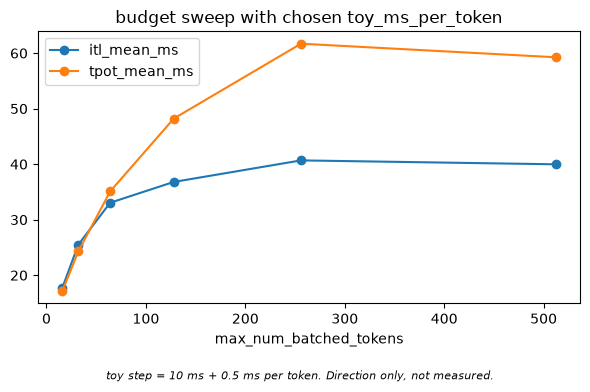

In [22]:
TOY_MS_PER_TOKEN = 0.5  # 여기를 0으로 바꿉니다
config = dataclasses.replace(budget_base, toy_ms_per_token=TOY_MS_PER_TOKEN)
rows = sweep(repeat_doc_workload(), "max_num_batched_tokens", BUDGETS, config)
print(toy_note(config))
view.sweep_chart(rows, "max_num_batched_tokens", ["itl_mean_ms", "tpot_mean_ms"],
                 note=toy_note(config), title="budget sweep with chosen toy_ms_per_token")

## 확인 질문

답은 여기 적지 않습니다. 자기 말로 설명해 보세요.

1. "decode를 전부 먼저"가 왜 부정확합니까? E1의 어떤 요청이 그 말로 설명되지 않습니까?
2. H200급에서 `vllm serve`의 기본 예산을 어떻게 찾습니까? `SchedulerConfig`의 값은 왜 답이 아닙니까?
3. threshold가 혼자 있는 요청에는 왜 적용되지 않습니까?
4. MTP 서버에서 client ITL을 token당 지연으로 읽으면 무엇이 틀립니까?
5. 서버 TTFT와 client TTFT가 다른 것은 왜 정상입니까?
6. 코드에 등록된 Counter 이름으로 `/metrics`를 찾으면 왜 찾지 못합니까? 그런데도 수업의 파서가 `_total`이 없는 형태까지 받는 이유는 무엇입니까?
7. 503과 preempt는 각각 어느 프로세스의 어떤 결정입니까?

## 블로그 함께 읽기

「Inside vLLM: 서버 시작부터 KV cache까지 소스 코드 톺아보기」, Jongsu Liam Kim, https://blog.liam.kim/posts/2026/10/Inside-vLLM/ (절 제목으로만 참조합니다).

| 블로그 절 | 읽을 때 볼 점 |
|---|---|
| 3. Engine config: CLI 인자에서 VllmConfig까지 | 표에 없는 보정이 있다(P3-06) |
| 설계 결정: 진입점마다 다른 batch 기본값 | PR #17885 수치의 조건을 확인한다 |
| 4. Schedule: step마다 계산할 token 배정 | P3-22와 대조한다 |
| 설계 결정: prefill과 decode의 구분 없는 scheduling | `doc` 표로 다시 설명해 본다 |
| 2. chunked prefill: 긴 prompt를 여러 step에 나누기 | P3-10의 조건을 덧붙인다 |
| SSE: 응답을 조금씩 보내는 방식 | 5절 지표 표와 잇는다 |

블로그는 측정 지표 정의와 `vllm bench serve`를 다루지 않습니다. 이 부분은 코드와 문서만 근거입니다.

## 정리

- `schedule()`은 running 큐를 먼저, preempt가 없었을 때만 waiting을 돕니다. 예산은 step마다 새로 채웁니다.
- `max_num_batched_tokens`는 한 step의 token 합, `max_num_seqs`는 running 수의 상한입니다. 기본값은 메모리, 장치 이름, 진입점으로 정해지고 `SchedulerConfig`의 값은 답이 아닙니다.
- chunked prefill은 모델이 지원할 때 켜지고, threshold는 긴 요청의 몫을 짧은 요청에 넘기는 교환입니다. 수업 그림은 방향만 보여 줍니다.
- 503은 API server의 거절이고 preempt는 scheduler의 결정입니다. 후자는 오류 없이 지연으로만 보입니다.
- 전체 입력 검사(`scheduler_reserve_full_isl`)는 기본이 켜짐입니다. `doc_faq_chat`의 block 5~10개에서 실제 `Scheduler`는 켠 쪽 preempt가 모두 0이었지만, 입장 때만 작동하므로 preempt를 없애는 설정은 아닙니다.
- TTFT, ITL, TPOT, E2EL은 client와 서버에서 시계가 다르고, ITL은 token당 지연이 아닙니다.
- `/metrics`는 정확한 이름으로, 전후 변화량으로 읽습니다. Counter의 노출 이름에는 `_total`이 붙습니다. 실험은 한 번에 한 변수만 바꿉니다.

**다음으로 넘기는 것.** preempt를 줄이는 길은 KV 공간이고, "block 하나의 byte 수가 용량을 정한다"는 사실이 다음 노트북 `04-Quantization.ipynb`의 출발점입니다.

## 참고한 근거

- Part 3: P3-01, P3-02, P3-03, P3-04, P3-05, P3-06, P3-07, P3-08, P3-09, P3-10, P3-11, P3-12, P3-13, P3-14, P3-15, P3-16, P3-17(미확인), P3-18, P3-19, P3-20, P3-21, P3-22, P3-23, P3-24, P3-25, P3-26, P3-27, P3-28, P3-29, P3-30, P3-31, P3-32, P3-33, P3-34, P3-35, P3-36, P3-37, P3-38, P3-39, P3-40, P3-41
- 다른 Part: P1-16, P1-34, P1-43, P2-37
- PDF 대조: D-03, D-04, D-05, D-07, D-11, D-15, D-17, D-18, D-19, D-20, D-21(미확인), D-36
- 수업 서버: R-01

출처 파일은 `Day07_new/docs/sources/part3.md`, `part1.md`, `part2.md`, `pdf-diff.md`입니다. 실제 클래스 실행 기록은 `Day07_new/data/reference_sched.json`과 `Day07_new/docs/reference/sched.md`입니다. 기준 소스는 vLLM v0.32.0, 커밋 `5df63a7203cdb9328d824a27b682e77c7b9928be`입니다. vLLM 서버를 띄운 적이 없습니다. 실제 `Scheduler` 클래스는 CPU에서 불렀고 모델 forward는 없습니다. `_total`(P3-38)은 prometheus_client 0.26.0을 실행해 확인한 것이고 vLLM 서버 출력이 아닙니다.